# Week 10 · Three Honest Tests, and GitHub
**The Evolution of Machine Learning and AI · SETU**

This week you **test your model honestly**, three ways: at **new points** it was never checked at; against **something that must always be true**; and with **the law 20% wrong**, to see whether the model's own score would warn you. Then you put your project on **GitHub**, with a README.

- Run the cells **in order** (Shift + Enter). You only type in cells marked ✏️ **YOUR TURN**.
- Your Part 2, 3 or 4 is **the same as before**: paste in your Week 8 YOUR TURN cell.

| Part | What it does | Who runs it |
|---|---|---|
| Step 0 | Loads the tools | everyone |
| Part A | Ask the Week 5 booklet: the search half of RAG (this week's topic) | everyone |
| Part 1 | The class example: the three tests, and the README results | everyone (just run it) |
| Part 2 | **Your tests**, if one thing changes over time | most of you |
| Part 3 | **Your tests**, if two or three things change each other | only if this is your law's shape |
| Part 4 | **Your tests**, if it changes over time and along a line | only if this is your law's shape |

## Step 0 · Load the tools (run once)
Just run it, and wait for *Ready*.

In [1]:
# ---------- Step 0 tools: run this cell once. You do not need to read or change it. ----------
import time
import numpy as onp                     # ordinary NumPy, for the answer sheet and the pictures
import jax, jax.numpy as np             # "np" is JAX here, so the model can learn from your law line
from jax import grad, jit, vmap
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
jax.config.update("jax_enable_x64", True)
plt.rcParams.update({"font.size": 23, "axes.titlesize": 25, "axes.labelsize": 24, "legend.fontsize": 20, "xtick.labelsize": 21, "ytick.labelsize": 21, "lines.markersize": 9, "lines.linewidth": 2.6})

def _init(sizes, seed=0):
    key = jax.random.PRNGKey(seed); params = []
    for m, n in zip(sizes[:-1], sizes[1:]):
        key, k = jax.random.split(key)
        params.append((jax.random.normal(k, (m, n)) * np.sqrt(1.0 / m), np.zeros(n)))
    return params

def _net(params, z):
    for W, b in params[:-1]:
        z = np.tanh(z @ W + b)
    W, b = params[-1]
    return z @ W + b

def _adam(loss, params, steps, lr):
    flat, unravel = jax.flatten_util.ravel_pytree(params)
    g_fn = jit(grad(lambda f, c: loss(unravel(f), c))); l_fn = jit(lambda f: loss(unravel(f), 1.0))
    m = onp.zeros_like(flat); v = onp.zeros_like(flat); hist = []
    for k in range(1, steps + 1):
        rate = lr * (0.05 + 0.95 * 0.5 * (1 + onp.cos(onp.pi * k / steps)))   # smaller steps as it goes
        g = onp.asarray(g_fn(flat, min(1.0, 0.15 + k / (0.6 * steps))))   # learn the early times first
        m = 0.9 * m + 0.1 * g; v = 0.999 * v + 0.001 * g * g
        flat = flat - rate * (m / (1 - 0.9 ** k)) / (onp.sqrt(v / (1 - 0.999 ** k)) + 1e-8)
        if k % 25 == 0 or k == 1: hist.append((k, float(l_fn(flat))))
    return unravel(flat), hist

import jax.flatten_util

def learn_law(rate, start, t_end, n_points=200, steps=3000, width=32, lr=0.01, seed=0):
    """Train a small network that obeys the law, with no data. Works for one thing or several."""
    start = np.atleast_1d(np.asarray(start, dtype=float)); k = start.shape[0]
    params = _init([1, width, width, k], seed)
    tau = np.linspace(0, 1, n_points)[:, None]                       # checking points, as fractions of t_end
    f = lambda t, y: np.atleast_1d(np.asarray(rate(t, y if k > 1 else y[0]), dtype=float))
    scale = np.maximum(np.abs(f(0.0, start if k > 1 else start)), 1e-6)  # keeps the leftover near 1
    f0 = f(0.0, start)                                                # the law's slope at the start
    size = np.maximum(np.maximum(np.abs(start), np.abs(f0) * t_end), 1e-3)   # the size of the answer
    def u(p, s): return start + s * t_end * f0 + s ** 2 * size * _net(p, s)   # the start and its slope are built in
    def leftover(p, s):
        du = jax.jacfwd(lambda z: u(p, z))(s)[:, 0] / t_end          # how fast the model changes
        return (du - f(s[0] * t_end, u(p, s))) / scale              # ... minus what the law says
    def loss(p, c):                                                    # c: how far along the time range to check
        w = jax.nn.sigmoid((c - tau[:, 0]) * 40.0)
        return np.sum(w[:, None] * vmap(lambda s: leftover(p, s))(tau) ** 2) / (np.sum(w) * k)
    t0 = time.time()
    best = None
    for attempt in range(3):                                          # if training gets stuck, start again
        params, hist = _adam(loss, _init([1, width, width, k], seed + attempt), steps, lr)
        if best is None or hist[-1][1] < best[1][-1][1]: best = (params, hist)
        if hist[-1][1] < 0.05: break
        print(f"  Training got stuck (loss {hist[-1][1]:.2g}); starting again from a different guess...")
    params, hist = best
    secs = time.time() - t0
    n_numbers = sum(W.size + b.size for W, b in params)
    make_model = lambda pp: (lambda t: onp.asarray(vmap(lambda s: u(pp, s))(np.asarray(t, dtype=float)[:, None] / t_end)))
    model = make_model(params)
    return dict(model=model, history=hist, seconds=secs, size=n_numbers, n_points=n_points, params=params, make_model=make_model)

def report(result, answer_t, answer_y, names, time_unit, check_time, check_tolerance, which=0, picture="my_first_model.png"):
    """Draw the loss curve and the model against the answer sheet, and run the success test."""
    t = onp.asarray(answer_t); Y = onp.atleast_2d(onp.asarray(answer_y)); M = result["model"](t).T
    err = float(onp.max(onp.abs(M - Y)))
    fig, ax = plt.subplots(1, 2, figsize=(15, 8))
    ks, ls = zip(*result["history"])
    ax[0].semilogy(ks, ls, color="#176B78", linewidth=2); ax[0].set_xlabel("training step"); ax[0].set_ylabel("loss (leftover)")
    ax[0].set_title("Loss curve"); ax[0].grid(alpha=0.3)
    for i, n in enumerate(names):
        ax[1].plot(t, Y[i], color="#E8B04B", linewidth=6, alpha=0.6, label=f"answer sheet: {n}")
        ax[1].plot(t, M[i], "--", color="#0B4651", linewidth=2, label=f"model: {n}")
    ax[1].axvline(check_time, color="#B3261E", linestyle=":", label="success test time")
    ax[1].set_xlabel(f"time ({time_unit})"); ax[1].set_title("Model against the answer sheet"); ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False); ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(picture, dpi=150, bbox_inches="tight"); plt.show()
    model_at = float(result["model"](onp.array([check_time]))[0][which])
    sheet_at = float(onp.interp(check_time, t, Y[which]))
    ok = abs(model_at - sheet_at) <= check_tolerance
    print(f"Biggest error against the answer sheet: {err:.4g}")
    print(f"Success test: at {check_time:g} {time_unit}, the model says {model_at:.4g} and the answer sheet says {sheet_at:.4g}.")
    print(f"  Difference {abs(model_at - sheet_at):.3g}, allowed {check_tolerance:g}: {'PASSED' if ok else 'NOT YET: try the four fixes'}")
    print(f"Training time: {result['seconds']:.0f} seconds. Model size: {result['size']} numbers. Checking points: {result['n_points']}.")
    print(f"Saved as {picture}.")
    return dict(error=err, passed=ok, seconds=result["seconds"], size=result["size"])

def learn_line_law(line_law, u0, L, t_end, ends=None, n_points=3000, steps=3000, width=32, lr=0.005, seed=0):
    """Train a network u(x, t) that obeys a law along a line. line_law(u, u_x, u_xx) gives how fast u changes."""
    params = _init([2, width, width, width, 1], seed)
    key = jax.random.PRNGKey(seed + 1)
    pts = jax.random.uniform(key, (n_points, 2))                     # checking points: (place, time) as fractions
    du0 = grad(lambda xx: u0(xx)); ddu0 = grad(du0)
    rate0 = lambda xx: line_law(u0(xx), du0(xx), ddu0(xx))           # the law's slope at the start, along the line
    size = float(onp.max(onp.abs(onp.asarray(vmap(rate0)(np.linspace(0.0, L, 201)))))) * t_end + 1e-3
    def u(p, xs, ts):          # start and its slope built in; the two ends stay fixed (the factor xs * (1 - xs))
        edge = 4.0 * xs * (1.0 - xs)
        return u0(xs * L) + edge * (ts * t_end * rate0(xs * L) + ts ** 2 * size * _net(p, np.array([xs, ts]))[0])
    def leftover(p, z):
        xs, ts = z[0], z[1]
        u_t = grad(u, 2)(p, xs, ts) / t_end
        u_x = grad(u, 1)(p, xs, ts) / L
        u_xx = grad(grad(u, 1), 1)(p, xs, ts) / L ** 2
        return (u_t - line_law(u(p, xs, ts), u_x, u_xx)) * t_end / (size + 1e-9)
    def loss(p, c):
        w = jax.nn.sigmoid((c - pts[:, 1]) * 40.0)
        return np.sum(w * vmap(lambda z: leftover(p, z))(pts) ** 2) / np.sum(w)
    t0 = time.time(); best = None
    for attempt in range(3):                                          # if training gets stuck, start again
        params, hist = _adam(loss, _init([2, width, width, width, 1], seed + attempt), steps, lr)
        if best is None or hist[-1][1] < best[1][-1][1]: best = (params, hist)
        if hist[-1][1] < 1.5e-3: break
        print(f"  Training got stuck (loss {hist[-1][1]:.2g}); starting again from a different guess...")
    params, hist = best; secs = time.time() - t0
    n_numbers = sum(W.size + b.size for W, b in params)
    model = lambda x, t: onp.asarray(vmap(lambda xs: u(params, xs, t / t_end))(np.asarray(x, dtype=float) / L))
    return dict(model=model, history=hist, seconds=secs, size=n_numbers, n_points=n_points)

def line_answer_sheet(line_law, u0, L, t_end, times, N=101):
    """The answer sheet for a law along a line, from the standard solver (the two ends stay fixed)."""
    x = onp.linspace(0, L, N); dx = x[1] - x[0]
    def rates(t, uu):
        u_x = onp.gradient(uu, dx); u_xx = onp.zeros_like(uu)
        u_xx[1:-1] = (uu[2:] - 2 * uu[1:-1] + uu[:-2]) / dx ** 2
        du = onp.asarray(line_law(uu, u_x, u_xx), dtype=float); du[0] = 0.0; du[-1] = 0.0
        return du
    sol = solve_ivp(rates, (0, t_end), onp.asarray(u0(x), dtype=float), t_eval=times, method="BDF")
    return x, sol.y

def line_report(result, x, sheet, times, name, check_place, check_time, check_tolerance, picture="my_first_model.png"):
    fig, ax = plt.subplots(1, 2, figsize=(15, 8))
    ks, ls = zip(*result["history"])
    ax[0].semilogy(ks, ls, color="#176B78", linewidth=2); ax[0].set_xlabel("training step"); ax[0].set_ylabel("loss (leftover)"); ax[0].set_title("Loss curve"); ax[0].grid(alpha=0.3)
    err = 0.0
    for j, tt in enumerate(times):
        m = result["model"](x, tt); err = max(err, float(onp.max(onp.abs(m - sheet[:, j]))))
        ax[1].plot(x, sheet[:, j], color="#E8B04B", linewidth=5, alpha=0.6)
        ax[1].plot(x, m, "--", color="#0B4651", linewidth=1.8, label=f"time {tt:g}")
    ax[1].set_xlabel("position along the line"); ax[1].set_ylabel(name); ax[1].set_title("Model (dashed) against the answer sheet (thick)"); ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=5, frameon=False); ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(picture, dpi=150, bbox_inches="tight"); plt.show()
    j = list(times).index(check_time)
    model_at = float(result["model"](onp.array([check_place]), check_time)[0]); sheet_at = float(onp.interp(check_place, x, sheet[:, j]))
    ok = abs(model_at - sheet_at) <= check_tolerance
    print(f"Biggest error against the answer sheet: {err:.4g}")
    print(f"Success test: at place {check_place:g}, time {check_time:g}, the model says {model_at:.4g} and the answer sheet says {sheet_at:.4g}.")
    print(f"  Difference {abs(model_at - sheet_at):.3g}, allowed {check_tolerance:g}: {'PASSED' if ok else 'NOT YET: try the four fixes'}")
    print(f"Training time: {result['seconds']:.0f} seconds. Model size: {result['size']} numbers. Checking points: {result['n_points']}.")
    return dict(error=err, passed=ok)




# ---------- Week 9: the comparison ----------
def make_examples(sheet_t, sheet_y, n, t_max=None, noise=0.02, seed=1):
    """n examples taken from the answer sheet (evenly spread up to t_max), with a little noise, like real measurements."""
    sheet_t = onp.asarray(sheet_t); Y = onp.atleast_2d(onp.asarray(sheet_y))
    t_max = sheet_t[-1] if t_max is None else t_max
    te = onp.linspace(sheet_t[0], t_max, n)
    ye = onp.stack([onp.interp(te, sheet_t, row) for row in Y])
    rng = onp.random.default_rng(seed)
    ye = ye + noise * (Y.max(axis=1, keepdims=True) - Y.min(axis=1, keepdims=True)) * rng.standard_normal(ye.shape)
    return te, ye

def learn_examples(te, ye, t_end, steps=3000, width=32, lr=0.01, seed=0):
    """An ordinary model: the same size and training as yours, but it learns from examples, not from the law."""
    ye = onp.atleast_2d(ye); k = ye.shape[0]
    mu = ye.mean(axis=1); sd = ye.std(axis=1) + 1e-9
    X = np.asarray(te, dtype=float)[:, None] / t_end; Yn = np.asarray(((ye.T - mu) / sd), dtype=float)
    def loss(p, c): return np.mean((vmap(lambda s: _net(p, s))(X) - Yn) ** 2)
    t0 = time.time(); params, hist = _adam(loss, _init([1, width, width, k], seed), steps, lr); secs = time.time() - t0
    n_numbers = sum(W.size + b.size for W, b in params)
    model = lambda t: onp.asarray(vmap(lambda s: _net(params, s))(np.asarray(t, dtype=float)[:, None] / t_end)) * sd + mu
    return dict(model=model, history=hist, seconds=secs, size=n_numbers)

def time_per_answer(predict, t, repeats=20):
    predict(t)                                                  # warm up
    t0 = time.time()
    for _ in range(repeats): predict(t)
    return (time.time() - t0) / (repeats * len(t))

def compare(law_result, rate, start, t_end, sheet_t, sheet_y, names, time_unit, counts=(4, 8, 16, 32, 64), picture="my_comparison.png"):
    """Race your law-learner against example-learners trained on 4 to 64 examples."""
    T = onp.asarray(sheet_t); Y = onp.atleast_2d(onp.asarray(sheet_y)); k = Y.shape[0]
    err = lambda M: float(onp.max(onp.abs(M.T - Y)))
    law_err = err(law_result["model"](T))
    rows = []; ex_models = {}
    for n in counts:
        te, ye = make_examples(T, Y, n)
        ex = learn_examples(te, ye, t_end); ex_models[n] = ex
        rows.append((n, err(ex["model"](T)), ex["seconds"], ex["size"]))
    f = (lambda tt, y: onp.asarray([float(v) for v in onp.atleast_1d(rate(tt, y if k > 1 else y[0]))]))
    def solver(tq): return solve_ivp(f, (0, t_end), onp.atleast_1d(start).astype(float), t_eval=onp.sort(tq), rtol=1e-8, atol=1e-10).y
    tq = onp.linspace(0, t_end, 1000)
    tpa = {"law": time_per_answer(law_result["model"], tq), "ex": time_per_answer(ex_models[counts[-1]]["model"], tq), "solver": time_per_answer(solver, tq, repeats=3)}
    fig, ax = plt.subplots(1, 2, figsize=(15, 8))
    ax[0].loglog([r[0] for r in rows], [r[1] for r in rows], "o-", color="#B3261E", linewidth=2, label="learns from examples")
    ax[0].axhline(law_err, color="#176B78", linewidth=2.5, label="learns from the law (no examples)")
    ax[0].set_xlabel("number of examples"); ax[0].set_ylabel("biggest error"); ax[0].set_title("Error against number of examples"); ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=1, frameon=False); ax[0].grid(alpha=0.3, which="both")
    for i, n_ in enumerate(names):
        ax[1].plot(T, Y[i], color="#E8B04B", linewidth=6, alpha=0.6, label=f"answer sheet: {n_}")
        ax[1].plot(T, law_result["model"](T)[:, i], "--", color="#0B4651", linewidth=2, label="learns from the law")
        ax[1].plot(T, ex_models[counts[0]]["model"](T)[:, i], ":", color="#B3261E", linewidth=2, label=f"learns from {counts[0]} examples")
    ax[1].set_xlabel(f"time ({time_unit})"); ax[1].set_title("The two models against the answer sheet"); ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=1, frameon=False); ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(picture, dpi=150, bbox_inches="tight"); plt.show()
    print(f"{'Model':34s}{'Examples':>10s}{'Biggest error':>16s}{'Size (numbers)':>16s}")
    print(f"{'Learns from the law':34s}{0:>10d}{law_err:>16.4g}{law_result['size']:>16d}")
    for n, e, s, z in rows: print(f"{'Learns from examples':34s}{n:>10d}{e:>16.4g}{z:>16d}")
    print(f"\nTime per answer: law model {tpa['law'] * 1e6:.1f} µs, example model {tpa['ex'] * 1e6:.1f} µs, standard solver {tpa['solver'] * 1e6:.1f} µs")
    caught = [n for n, e, _, _ in rows if e <= law_err]
    print("Finding:", f"the example-learner needed {caught[0]} examples to be as accurate as the law-learner." if caught else f"even with {counts[-1]} examples, the example-learner was less accurate than the law-learner (error {rows[-1][1]:.3g} against {law_err:.3g}).")
    print(f"Saved as {picture}.")
    return dict(law_error=law_err, rows=rows, time_per_answer=tpa, caught_up_at=caught[0] if caught else None)

def outside_range(law_result, sheet_t, sheet_y, t_end, names, time_unit, share=0.6, n=32, picture="my_outside_range.png"):
    """Examples only from the first part of the time range: which model still works after that?"""
    T = onp.asarray(sheet_t); Y = onp.atleast_2d(onp.asarray(sheet_y)); cut = share * t_end
    te, ye = make_examples(T, Y, n, t_max=cut)
    ex = learn_examples(te, ye, t_end)
    after = T > cut
    e_law = float(onp.max(onp.abs(law_result["model"](T)[after].T - Y[:, after])))
    e_ex = float(onp.max(onp.abs(ex["model"](T)[after].T - Y[:, after])))
    plt.figure(figsize=(13, 7)); plt.axvspan(cut, t_end, color="#EEEEEE", label="no examples measured here")
    for i, n_ in enumerate(names):
        plt.plot(T, Y[i], color="#E8B04B", linewidth=6, alpha=0.6, label=f"answer sheet: {n_}")
        plt.plot(T, law_result["model"](T)[:, i], "--", color="#0B4651", linewidth=2, label="learns from the law")
        plt.plot(T, ex["model"](T)[:, i], ":", color="#B3261E", linewidth=2.5, label=f"learns from {n} examples")
    plt.plot(te, ye[0], "o", color="#B3261E", markersize=6, label="the examples")
    plt.xlabel(f"time ({time_unit})"); plt.title("Outside the range of the examples"); plt.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False); plt.grid(alpha=0.3)
    plt.savefig(picture, dpi=150, bbox_inches="tight"); plt.show()
    print(f"After {cut:g} {time_unit} (no examples there): law-learner error {e_law:.4g}, example-learner error {e_ex:.4g}.")
    return dict(law=e_law, examples=e_ex)

def _quantise(params, bits):
    out = []
    for W, b in params:
        q = []
        for A in (W, b):
            m = float(np.max(np.abs(A))) + 1e-12; levels = 2 ** (bits - 1) - 1
            q.append(np.round(A / m * levels) / levels * m)
        out.append(tuple(q))
    return out

def shrink(rate, start, t_end, sheet_t, sheet_y, time_unit, check_time, check_tolerance, which=0, widths=(32, 16, 8, 4, 2), bits=(32, 16, 8, 4, 2)):
    """Make the model smaller (fewer numbers, then fewer digits per number) until it fails your success test."""
    T = onp.asarray(sheet_t); Y = onp.atleast_2d(onp.asarray(sheet_y))
    sheet_at = float(onp.interp(check_time, T, Y[which]))
    print(f"{'Width':>6s}{'Numbers':>9s}{'Bits each':>11s}{'Size (bytes)':>14s}{'At check time':>15s}   Success test")
    best = None
    for w in widths:
        r = learn_law(rate, start, t_end, width=w)
        at = float(r["model"](onp.array([check_time]))[0][which]); ok = abs(at - sheet_at) <= check_tolerance
        print(f"{w:>6d}{r['size']:>9d}{32:>11d}{r['size'] * 4:>14d}{at:>15.4g}   {'PASSED' if ok else 'not yet'}")
        if ok: best = (w, r)
        else: break
    if best is None:
        print("Even the full-size model did not pass: go back to the four fixes."); return None
    w, r = best
    params = r["params"]; last_ok = (32, r["size"] * 4)
    for b in bits[1:]:
        qp = _quantise(params, b); at = float(r["make_model"](qp)(onp.array([check_time]))[0][which]); ok = abs(at - sheet_at) <= check_tolerance
        print(f"{w:>6d}{r['size']:>9d}{b:>11d}{r['size'] * b // 8:>14d}{at:>15.4g}   {'PASSED' if ok else 'not yet'}")
        if ok: last_ok = (b, r["size"] * b // 8)
        else: break
    print(f"\nSmallest model that passes: width {w}, {r['size']} numbers at {last_ok[0]} bits each = {last_ok[1]} bytes.")
    return dict(width=w, numbers=r["size"], bits=last_ok[0], bytes=last_ok[1])

def line_compare(law_result, x, sheet, times, L, t_end, name, counts=(25, 100, 400), noise=0.02, picture="my_comparison.png"):
    """Part 4: race the law-learner against example-learners trained on noisy (place, time) examples."""
    X, Tm = onp.meshgrid(x, onp.asarray(times, dtype=float)); Z = sheet.T
    err_law = max(float(onp.max(onp.abs(law_result["model"](x, tt) - sheet[:, j]))) for j, tt in enumerate(times))
    rng = onp.random.default_rng(1); rows = []; last = None
    for n in counts:
        idx = rng.choice(X.size, n, replace=False)
        P = onp.stack([X.ravel()[idx] / L, Tm.ravel()[idx] / t_end], 1); V = Z.ravel()[idx] + noise * onp.ptp(Z) * rng.standard_normal(n)
        mu, sd = V.mean(), V.std() + 1e-9; Pj = np.asarray(P); Vj = np.asarray((V - mu) / sd)
        loss = lambda p, c: np.mean((vmap(lambda z: _net(p, z)[0])(Pj) - Vj) ** 2)
        t0 = time.time(); params, _ = _adam(loss, _init([2, 32, 32, 32, 1], 0), 3000, 0.005); secs = time.time() - t0
        mdl = lambda xx, tt, params=params, mu=mu, sd=sd: onp.asarray(vmap(lambda xs: _net(params, np.array([xs / L, tt / t_end]))[0])(np.asarray(xx, dtype=float))) * sd + mu
        e = max(float(onp.max(onp.abs(mdl(x, tt) - sheet[:, j]))) for j, tt in enumerate(times))
        rows.append((n, e, sum(W.size + b.size for W, b in params))); last = mdl
    plt.figure(figsize=(11, 6))
    plt.loglog([r[0] for r in rows], [r[1] for r in rows], "o-", color="#B3261E", linewidth=2, label="learns from examples")
    plt.axhline(err_law, color="#176B78", linewidth=2.5, label="learns from the law (no examples)")
    plt.xlabel("number of examples"); plt.ylabel("biggest error"); plt.title("Error against number of examples"); plt.legend(); plt.grid(alpha=0.3, which="both")
    plt.savefig(picture, dpi=150, bbox_inches="tight"); plt.show()
    print(f"{'Model':26s}{'Examples':>10s}{'Biggest error':>16s}{'Size (numbers)':>16s}")
    print(f"{'Learns from the law':26s}{0:>10d}{err_law:>16.4g}{law_result['size']:>16d}")
    for n, e, z in rows: print(f"{'Learns from examples':26s}{n:>10d}{e:>16.4g}{z:>16d}")
    caught = [n for n, e, _ in rows if e <= err_law]
    print("Finding:", f"the example-learner needed {caught[0]} examples to match the law-learner." if caught else f"even with {counts[-1]} examples, the example-learner was less accurate (error {rows[-1][1]:.3g} against {err_law:.3g}).")
    return dict(law_error=err_law, rows=rows)

def line_shrink(line_law, u0, L, t_end, x, sheet, times, check_place, check_time, check_tolerance, widths=(16, 8)):
    """Part 4: fewer numbers until the success test fails."""
    j = list(times).index(check_time); sheet_at = float(onp.interp(check_place, x, sheet[:, j])); best = None
    print(f"{'Width':>6s}{'Numbers':>9s}{'At check point':>16s}   Success test")
    for w in widths:
        r = learn_line_law(line_law, u0, L, t_end, width=w)
        at = float(r["model"](onp.array([check_place]), check_time)[0]); ok = abs(at - sheet_at) <= check_tolerance
        print(f"{w:>6d}{r['size']:>9d}{at:>16.4g}   {'PASSED' if ok else 'not yet'}")
        if ok: best = (w, r["size"])
        else: break
    if best: print(f"\nSmallest model that passes: width {best[0]}, {best[1]} numbers ({best[1] * 4} bytes).")
    return best



# ---------- Week 10: three honest tests ----------
from scipy.optimize import minimize_scalar

def new_points_test(result, sheet_t, sheet_y, t_end, names, time_unit, picture="test_new_points.png"):
    """Test 1: the error at the checking points, and at 1,000 new points the model was never checked at."""
    n = result.get("n_points", 200)
    tc = onp.linspace(0, t_end, n); tn = onp.sort(onp.random.default_rng(7).uniform(0, t_end, 1000))
    T = onp.asarray(sheet_t); Y = onp.atleast_2d(onp.asarray(sheet_y))
    yc = onp.stack([onp.interp(tc, T, r) for r in Y]); yn = onp.stack([onp.interp(tn, T, r) for r in Y])
    ec = float(onp.max(onp.abs(result["model"](tc).T - yc))); en = float(onp.max(onp.abs(result["model"](tn).T - yn)))
    plt.figure(figsize=(13, 7.6))
    plt.semilogy(tn, onp.max(onp.abs(result["model"](tn).T - yn), axis=0) + 1e-12, ".", color="#B3261E", markersize=5, label="error at 1,000 new points")
    plt.semilogy(tc, onp.max(onp.abs(result["model"](tc).T - yc), axis=0) + 1e-12, "o", color="#176B78", markersize=7, label=f"error at the {n} checking points")
    plt.xlabel(f"time ({time_unit})"); plt.ylabel("error"); plt.title("Test 1 · New points"); plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False); plt.grid(alpha=0.3)
    plt.savefig(picture, dpi=150, bbox_inches="tight"); plt.show()
    print(f"Test 1 · New points: biggest error at the checking points {ec:.4g}; at 1,000 new points {en:.4g}.")
    print("  " + ("PASSED: the model is just as good between the checking points." if en <= 2 * ec + 1e-9 else "CAREFUL: the model is worse between the checking points. More checking points may help."))
    return dict(checking=ec, new=en)

def must_hold_test(result, t_end, must_hold, names, time_unit, picture="test_must_hold.png", lines=()):
    """Test 2: something that must always be true, checked at 2,000 moments."""
    t = onp.linspace(0, t_end, 2000); Y = result["model"](t)                       # (2000, k)
    dY = onp.gradient(Y, t, axis=0)
    y_arg = Y[:, 0] if Y.shape[1] == 1 else Y.T; dy_arg = dY[:, 0] if Y.shape[1] == 1 else dY.T
    ok = onp.asarray(must_hold(t, y_arg, dy_arg), dtype=bool)
    share = float(ok.mean()); bad = ~ok
    plt.figure(figsize=(13, 7.6))
    for i, n_ in enumerate(names): plt.plot(t, Y[:, i], color="#176B78", linewidth=2.5, label=f"model: {n_}")
    for v, lab in lines: plt.axhline(v, color="#A96E08", linestyle="--", linewidth=2, label=lab)
    if bad.any(): plt.plot(t[bad], Y[bad, 0], "o", color="#B3261E", markersize=5, label="where the rule is broken")
    plt.xlabel(f"time ({time_unit})"); plt.title("Test 2 · Something that must always be true"); plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False); plt.grid(alpha=0.3)
    plt.savefig(picture, dpi=150, bbox_inches="tight"); plt.show()
    print(f"Test 2 · Must always be true: the rule holds at {share * 100:.1f}% of 2,000 moments.")
    print("  " + ("PASSED." if share == 1.0 else f"BROKEN at {int(bad.sum())} moments, first at {t[bad][0]:.3g} {time_unit}. Say so in your report: is it a real problem, or a tiny wobble?"))
    return dict(share=share)

def wrong_law_test(rate, start, t_end, number_name, g, sheet_t, sheet_y, time_unit, check_time, which=0, factor=1.2, right_result=None, picture="test_wrong_law.png"):
    """Test 3: change one number in the law by 20%. How far does the answer move? Would the model's own score warn you?"""
    T = onp.asarray(sheet_t); Y = onp.atleast_2d(onp.asarray(sheet_y))
    right = right_result or learn_law(rate, start, t_end)
    true_value = g[number_name]; g[number_name] = true_value * factor
    try: wrong = learn_law(rate, start, t_end)
    finally: g[number_name] = true_value
    at_sheet = float(onp.interp(check_time, T, Y[which])); at_wrong = float(wrong["model"](onp.array([check_time]))[0][which])
    plt.figure(figsize=(13, 7.6))
    plt.plot(T, Y[which], color="#E8B04B", linewidth=7, alpha=0.6, label="the answer sheet (the true law)")
    plt.plot(T, right["model"](T)[:, which], "--", color="#0B4651", linewidth=2.5, label="model: the right law")
    plt.plot(T, wrong["model"](T)[:, which], ":", color="#B3261E", linewidth=3, label=f"model: {number_name} {int(round((factor - 1) * 100)):+d}%")
    plt.axvline(check_time, color="#888888", linestyle=":")
    plt.xlabel(f"time ({time_unit})"); plt.title("Test 3 · The wrong-law test"); plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False); plt.grid(alpha=0.3)
    plt.savefig(picture, dpi=150, bbox_inches="tight"); plt.show()
    lr, lw = right["history"][-1][1], wrong["history"][-1][1]
    print(f"Test 3 · Wrong law: with {number_name} {int(round((factor - 1) * 100)):+d}%, the answer at {check_time:g} {time_unit} moves from {at_sheet:.4g} to {at_wrong:.4g} (a change of {abs(at_wrong - at_sheet):.3g}).")
    print(f"  The model's own score (loss): right law {lr:.1e}, wrong law {lw:.1e}. " + ("The score did NOT warn you: the wrong-law model obeys its wrong law just as well." if lw < 10 * lr + 1e-6 else "The score was worse, but it cannot tell you the law itself is wrong."))
    return dict(moved=abs(at_wrong - at_sheet), loss_right=lr, loss_wrong=lw)

def find_number(rate, start, t_end, number_name, g, sheet_t, sheet_y, n=5, noise=0.02, which=0):
    """Optional: pretend one number is unknown, and find it from n noisy readings."""
    T = onp.asarray(sheet_t); Y = onp.atleast_2d(onp.asarray(sheet_y))
    te, ye = make_examples(T, Y, n, noise=noise, seed=3)
    true_value = g[number_name]; k = Y.shape[0]
    def misfit(v):
        g[number_name] = v
        try:
            sol = solve_ivp(lambda tt, y: onp.asarray([float(q) for q in onp.atleast_1d(rate(tt, y if k > 1 else y[0]))]), (0, t_end), onp.atleast_1d(start).astype(float), t_eval=te, rtol=1e-8, atol=1e-10)
            return float(onp.sum((sol.y - ye) ** 2)) if sol.success else 1e12
        finally: g[number_name] = true_value
    res = minimize_scalar(misfit, bounds=(0.2 * abs(true_value), 5 * abs(true_value)), method="bounded")
    est = res.x if true_value > 0 else -res.x
    print(f"Optional · From {n} noisy readings, {number_name} is estimated as {est:.4g} (the true value is {true_value:.4g}; off by {abs(est - true_value) / abs(true_value) * 100:.1f}%).")
    return dict(estimate=est, true=true_value)

def readme_results(name, t1, t2, t3, leaves_out):
    """Print a Results section to paste into your GitHub README."""
    print("\n---------- paste this into your README.md, under ## Checks ----------\n")
    print("| Check | Result |\n|---|---|")
    print(f"| New points | Biggest error {t1['checking']:.3g} at the checking points, {t1['new']:.3g} at 1,000 new points |")
    print(f"| Must always be true | Holds at {t2['share'] * 100:.1f}% of 2,000 moments |")
    print(f"| 20% wrong-law test | The answer moves by {t3['moved']:.3g}; the model's own score did not warn us |")
    print(f"\n**What the law leaves out:** {leaves_out}")

# ---------- Part A: search the booklet (the retrieval in RAG) ----------
def build_search(passages):
    from sklearn.feature_extraction.text import TfidfVectorizer
    vec = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), sublinear_tf=True)
    M = vec.fit_transform([p["text"] for p in passages])
    return dict(vec=vec, M=M, passages=passages)

def ask(search, question, top=3):
    """Turn the question into numbers, find the passages with the most similar numbers, and show where they are."""
    q = search["vec"].transform([question]); scores = (search["M"] @ q.T).toarray()[:, 0]
    best = onp.argsort(-scores)[:top]
    print(f"Question: {question}\n")
    for r, i in enumerate(best, 1):
        p = search["passages"][i]
        print(f"{r}. Page {p['page']} (similarity {scores[i]:.2f}): {p['text'][:300]}{'...' if len(p['text']) > 300 else ''}\n")
    print("Now check: open the booklet at that page. Does the passage really answer your question?")
    return [search["passages"][i]["page"] for i in best]

# ---------- Part 4 versions ----------
def line_tests(line_law, u0, L, t_end, result, x, sheet, times, must_hold, wrong_number, g, check_place, check_time, name):
    """Part 4: new points along the line, something that must always be true, and the wrong-law test."""
    rng = onp.random.default_rng(7); xn = onp.sort(rng.uniform(0, L, 500))
    e_grid = max(float(onp.max(onp.abs(result["model"](x, tt) - sheet[:, j]))) for j, tt in enumerate(times))
    e_new = max(float(onp.max(onp.abs(result["model"](xn, tt) - onp.interp(xn, x, sheet[:, j])))) for j, tt in enumerate(times))
    print(f"Test 1 · New points: biggest error on the grid {e_grid:.4g}; at 500 new places {e_new:.4g}.")
    tt_ = onp.linspace(0, t_end, 60); U = onp.stack([result["model"](x, s) for s in tt_])
    ok = onp.asarray(must_hold(x, U), dtype=bool); print(f"Test 2 · Must always be true: holds at {ok.mean() * 100:.1f}% of {ok.size} place-and-time points.")
    true_value = g[wrong_number]; g[wrong_number] = true_value * 1.2
    try: wrong = learn_line_law(line_law, u0, L, t_end)
    finally: g[wrong_number] = true_value
    j = list(times).index(check_time); at_sheet = float(onp.interp(check_place, x, sheet[:, j])); at_wrong = float(wrong["model"](onp.array([check_place]), check_time)[0])
    plt.figure(figsize=(13, 7.6)); plt.plot(x, sheet[:, j], color="#E8B04B", linewidth=7, alpha=0.6, label="the answer sheet (the true law)")
    plt.plot(x, result["model"](x, check_time), "--", color="#0B4651", linewidth=2.5, label="model: the right law")
    plt.plot(x, wrong["model"](x, check_time), ":", color="#B3261E", linewidth=3, label=f"model: {wrong_number} +20%")
    plt.xlabel("position along the line"); plt.ylabel(name); plt.title(f"Test 3 · The wrong-law test, at time {check_time:g}"); plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False); plt.grid(alpha=0.3)
    plt.savefig("test_wrong_law.png", dpi=150, bbox_inches="tight"); plt.show()
    print(f"Test 3 · Wrong law: with {wrong_number} +20%, the answer at place {check_place:g}, time {check_time:g} moves from {at_sheet:.4g} to {at_wrong:.4g}. Model's own score: right {result['history'][-1][1]:.1e}, wrong {wrong['history'][-1][1]:.1e}.")
    return dict(checking=e_grid, new=e_new), dict(share=float(ok.mean())), dict(moved=abs(at_wrong - at_sheet))

print("Ready: the tools are loaded. Now run the next cell.")

Ready: the tools are loaded. Now run the next cell.


## Part A · Ask the booklet (this week's topic, 15 minutes)
A **retrieval-augmented** system first **searches your own documents** for the passages most like your question, then hands them to a language model to write the answer, like an open-book exam. This part is the **search**: it turns every passage of the Week 5 core booklet into a list of numbers, turns your question into numbers the same way, and shows the passages whose numbers are most alike, **with their page numbers**.

Run the next cell, then ask **two questions** of your own in the cell after it. Check one answer against the booklet page it points to.

In [2]:
PASSAGES = [{"page": 3, "text": "1 A law is not a pattern COVERS Lecture Part 1 · Lab Exercise 1 TIME 7 minutes IN BRIEF A pattern in data is a nudge. A law of nature is a wall: exactly true, everywhere, whether or not you have data. Tell a model the law and it can learn with no data at all. WO R D S I N T H I S C H A P T E R , I N P L A I N E N G L I S H a pattern something usually true in the data you happen to have, like \"nearby pixels belong together\" a law something always true, exactly, whether or not you have any data a prior, a guess what a model is told before it sees data; Week 4's inductive bias a constraint a guess so firm it removes answers entirely, instead of nudging away from them error on the truth how far the model's answer is from the real one, on average; smaller is better the data regime how much data you have; the lever that decides which methods work 1.1 The one picture: marking homework without the answer sheet Figure 1: The homework is marked wrong without the answer sheet: put the answer back into the question."}, {"page": 3, "text": "You are marking a maths test and you have lost the answer sheet. The question: find the number whose square is 9. A student wrote 4. Can you mark it? Yes. Put 4 back into the question: 4 × 4 = 16, and 16 is not 9. Wrong. You never needed the answer sheet. That is the whole of this week. An equation is a question you can put an answer back into. A model’s guess can be checked against an equation anywhere you like, even where nobody has ever taken a measurement, because checking does not require knowing the answer. And it connects to Week 3 in one line: the loop was guess, check, blame, nudge, and this week only the check changes. Instead of “how far from the measurement?” it asks “how far from obeying the law?”."}, {"page": 4, "text": "1.2 Two kinds of advice Figure 2: Left: a pattern nudges towards a likely answer, and every answer stays possible. Right: a law is a wall; a whole side of answers is gone for good. E V E RY DAY A NA L O GY “People in high-visibility jackets are often construction workers.” Useful, usually right, sometimes wrong. It rules out nothing; you still have to look at every case. That is a nudge."}, {"page": 4, "text": "“This person is standing in Dublin, so they are not in Cork.” Not a hint. A whole set of answers is gone for good, and no new evidence about the jacket brings it back. That is a wall. A pattern gives a model a nudge towards answers that have usually been right. A law gives it a wall: a region of answers that is simply excluded. Week 4 gave models nudges. This week gives them walls."}, {"page": 4, "text": "1.3 The one equation of the week, in words Figure 3: A weight on a spring: pull it down, let go, and it bobs up and down a little less each time until it settles. Hang a weight on a spring, pull it down, let go. It bobs up and down, a little less each time, until it stops. Three things decide how it moves: how heavy the weight is (𝑚), how much friction slows it (𝑐), and how stiff the spring is (𝑘). The rule it obeys, in words: the weight times how fast the speed is changing, plus the friction times the speed, plus the stiffness times the position, always adds up to exactly zero. In symbols, so you recognise it:"}, {"page": 5, "text": "𝑚𝑢″ + 𝑐𝑢′ + 𝑘𝑢 = 0 𝑢 is the position, 𝑢′ is the speed (how fast the position is changing) and 𝑢″ is how fast the speed is changing. You will never solve this. You only need one fact about it: it is a question you can put an answer back into. Give any guess for the position over time, and the equation tells you how badly the guess breaks the rule at any moment, without knowing the right answer."}, {"page": 5, "text": "1.4 The result that sets up the week Same network. Same number of dials. Same optimiser. Same number of trips round the loop. The only difference is what the check compares the guess against. Figure 4: The data-only model improves with measurements and flattens out at about 0.026, the size of the noise. The physics-informed model, using zero measurements, scores 0.00135: twenty times better, and it cannot be plotted, because its position on the horizontal axis is zero."}, {"page": 5, "text": "model measurements it saw error on the truth data-only 64 0.026 physics-informed 0 0.00135 The physics-informed model never saw a single measurement of the thing it was predicting. It was told what the answer must satisfy instead of being shown examples of it. 1.5 Why this matters where you will work Week 4 ended with a Vision Transformer beating a stencil model given 300 million pictures, and losing given 1.3 million. You will not have 1.3 million labelled examples. You will have forty readings from one wind turbine, or two hundred patients from one hospital. In that world more data is not available at any price. The only lever left is what you already know, and engineering and science come with four centuries of extremely reliable knowledge that machine learning, until recently, made almost no use of."}, {"page": 6, "text": "★ FOR THE QUIZ ▪ A pattern is a nudge: usually right, eliminates nothing. A law is a wall: exactly true everywhere, and it removes whole sets of answers. ▪ An equation is a question you can put an answer back into. Checking a guess against it needs no answer sheet. ▪ Same network, same optimiser, different check: with zero measurements the physics-informed model scored 0.00135; with 64 measurements the data-only model scored 0.026."}, {"page": 6, "text": "▪ Where you will work, more data is not for sale, so what you already know is the only lever. E X T R A · O P T I O NA L · N O T O N T H E Q U I Z Detailed booklet Chapters 1 to 5: the formal statement of a prior against a constraint, reading a differential equation, and where scientific knowledge lives."}, {"page": 7, "text": "2 Checking the equation where there is no data COVERS Lecture Part 2 · Lab Exercise 2 TIME 9 minutes IN BRIEF The method in plain steps: put the guess back into the equation, square what is left over, and treat that as the loss. Only the check step changed. The one new trick is taking the slope of a slope, exactly. WO R D S I N T H I S C H A P T E R , I N P L A I N E N G L I S H residual how far a guess is from obeying the equation; zero means it obeys physics loss the residual, squared and averaged over many places; the new check step collocation points the places where the equation is checked; free, because no measurement is needed derivative, slope how fast something is changing; u′ is the speed, u″ is how fast the speed changes automatic differentiation the computer working out slopes exactly, by tracking every arithmetic step physics-informed network (PINN) an ordinary network whose check is an equation; not a new kind of network 2.1 The whole method, before any notation Figure 5: Measurements cost something, so you have few. Checks against the rule are free, so you can have as many as you like, anywhere."}, {"page": 7, "text": "Ordinary supervised learning compares the model against measurements, at the places you have measurements. Each dot cost somebody a sensor, an experiment, an afternoon. Physics-informed learning compares the model against an equation, at places where you have nothing at all. Each dot is free, because checking an equation does not require knowing the answer. So you can put a thousand checkpoints anywhere you like, including places where measuring is impossible."}, {"page": 7, "text": "2.2 What the check actually computes 1. Start with a time. There is no measurement attached to it, and there does not need to be. 2. The network produces its current guess for the position at that time. 3. Work out the speed, and how fast the speed is changing, from the network’s own guess: the slope of the network’s output with respect to its input, and the slope of that. This is the operation Weeks 3 and 4 never needed."}, {"page": 8, "text": "4. Put position, speed and change-of-speed into the equation. If the guess were the true motion, the sum would be exactly zero. Whatever it is instead is the residual, the leftover. Nowhere in those four steps does the true answer appear. Square the residual, average it over a few hundred times, and that is the entire loss. Then blame and nudge, exactly as in Week 3. E V E RY DAY A NA L O GY Try it with a pencil. Suppose the spring has 𝑚 = 1, 𝑐 = 0 (no friction) and 𝑘 = 1, and a student guesses that the position is always 0.7. Then the speed is 0 and the change of speed is 0, so the equation’s left side is 1 × 0 + 0 × 0 + 1 × 0.7 = 0.7. The leftover is 0.7, not 0, so the guess is wrong, and you found that out without knowing the right answer. The lab prints this exact check for three candidate answers."}, {"page": 8, "text": "Figure 6: Three guesses put back into the rule. The true motion leaves nothing over; forgetting friction leaves a little; a flat line leaves a lot. The rule did the marking. 2.3 Only one thing changed the loop’s step Weeks 3 and 4 this week the network an ordinary network the same guess input in, answer out the same check distance from the measurement how far from obeying the equation blame which dials caused it the same nudge turn the dials a little the same IN PLAIN ENGLISH A physics-informed network is not a new kind of network. There is no special layer and no special archi­ tecture. It is an ordinary network with an unusual check. If you go looking for “the PINN architecture” you will be confused, because there is none."}, {"page": 9, "text": "2.4 The one genuinely new trick Figure 7: Top: the slope of the position is the speed. Bottom: the slope of the speed is how fast the speed is changing. The rule needs both: the slope of a slope. The check needs the slope, and the slope of the slope. Then, to blame and nudge, the computer needs the slope of that with respect to every dial. Ordinary training software works out slopes as plain numbers, and you cannot take the slope of a number. The trick is to make the computer record how each slope was worked out, so that the slope is itself something you can take the slope of. The lab’s own 250-line engine does this; checked against slopes worked out by hand up to the third slope-of-a-slope, its worst error is 1.22e-16, the rounding error of the computer’s arithmetic. In PyTorch this is what create_graph=True means."}, {"page": 9, "text": "C O M M O N M I S TA K E Estimating the slope by nudging the input a tiny step and measuring the change. It works for a first slope and fails for the slope of a slope: a tiny difference divided by a tiny number squared is swamped by rounding. Measured in the lab: the exact engine gives −0.03664877 for a second derivative and the nudging method −0.03664985; the disagreement is the nudging method’s error."}, {"page": 9, "text": "★ FOR THE QUIZ ▪ A residual is how far a guess is from obeying the equation: put the guess back into the question and see what is left over. Zero means it obeys. ▪ A physics loss is the residual, squared and averaged at many collocation points, places where the equation is checked and no measurement is needed. No answer appears anywhere in it. ▪ A physics-informed network is an ordinary network with a different check; guess, blame and nudge are Week 3′s, unchanged."}, {"page": 9, "text": "▪ The one new trick: the computer must be able to take the slope of a slope, exactly. Nudging and measuring is not good enough. E X T R A · O P T I O NA L · N O T O N T H E Q U I Z Detailed booklet Chapters 6 to 9: the engine’s design, differentiating a derivative, and the PINN end to end."}, {"page": 10, "text": "3 What the law buys COVERS Lecture Part 3 · Lab Exercise 3 TIME 7 minutes IN BRIEF A model that knows the law keeps working beyond the data, because the law was known there too. And it inherits every consequence of the law, such as conservation of energy, whether or not you thought to check. WO R D S I N T H I S C H A P T E R , I N P L A I N E N G L I S H extrapolation answering outside the range where you had any measurements degradation how many times worse a model gets outside its data than inside; 1.0 means no worse energy for the spring: one number made from the speed and the position; you only need to know it is one number conservation a quantity that stays exactly the same over time when nothing is added or lost drift how far a model's version of a conserved quantity wanders from constant a consequence something the equation implies but nobody wrote into the loss 3.1 Beyond the data Both models get measurements on the first 40% of the time only. Both are scored on the rest."}, {"page": 10, "text": "Figure 8: Data on the left of the dotted line only. The data-only model does something smooth and arbitrary beyond it, and does not warn you. The physics-informed model follows the truth, because the equation was known out there too. model error where data existed error beyond the data how many times worse data-only 0.018 0.500 27.6 physics + the same data 0.0086 0.0087 1.0 E V E RY DAY A NA L O GY You are asked where a thrown ball will land, having watched only the first half-second of its flight. A model fitted to what you saw describes that half-second beautifully and has no opinion about the rest; stretched further, it does something smooth and arbitrary, and it does not warn you. A model that knows the ball is under gravity can tell you where it lands, because gravity applies for the whole flight. The second model is not stretching the data. It is following the law."}, {"page": 11, "text": "Figure 9: Watch only the start of a throw (thick line). Copying the shape of what you saw keeps going up (dashed); knowing gravity brings the ball down in the right place (green). 3.2 Something nobody put in the loss Take the friction away. Now the spring bobs for ever and its energy stays exactly the same the whole time. Nobody tells either model this. It is not in the loss, not in the network, not in the data."}, {"page": 11, "text": "model how far its energy drifted what that means data-only 16.3% physically impossible, and nothing flagged it physics + noisy data 5.1% better physics only, no data 0.2% kept constant a thing it was never told about A model that obeys the equation inherits everything the equation implies, whether or not you thought to check it. A model that fits points inherits agreement with those points, and nothing else. E V E RY DAY A NA L O GY Two students. One has memorised the worked examples; the other understands the subject. Both answer the questions they have seen. You find out which you have by asking a question that was not on the practice sheet."}, {"page": 11, "text": "Energy drift is that question, and it costs nothing to ask. Your test set covers the things you thought to measure; the law covers the things you did not. ★ FOR THE QUIZ ▪ Beyond the data: given measurements on the first 40% only, a data-only model got 27.6 times worse outside them; the physics-informed model got no worse (1.0), because the law was true out there too. ▪ A data-only model does not know that it does not know. It fails smoothly and silently outside its data."}, {"page": 11, "text": "▪ Conservation: a frictionless spring keeps its energy exactly. Nobody told either model. Data-only drifted 16.3%; physics-only drifted 0.2%. ▪ A model that obeys the equation inherits everything the equation implies. Checking a consequence you never trained on is how you tell a memoriser from an understander. E X T R A · O P T I O NA L · N O T O N T H E Q U I Z Detailed booklet Chapters 10 to 14: noise robustness, the heat equation (a two-input version), and the full write-ups."}, {"page": 12, "text": "4 What it costs, and the two ways it goes quietly wrong COVERS Lecture Part 4 · Lab Exercise 4 TIME 9 minutes IN BRIEF A soft penalty needs a weight nobody can derive; a hard constraint builds the condition into the arithmetic. A small loss only speaks for the places you checked. And a wrong law is worse than no law: the loss stays small while the answer goes wrong."}, {"page": 12, "text": "WO R D S I N T H I S C H A P T E R , I N P L A I N E N G L I S H initial condition where the spring starts and how fast it is moving at time zero soft penalty adding \"and please satisfy the start\" to the loss, with a weight saying how much it matters hard constraint writing the model so the start holds automatically, whatever the dials do the weight, λ the number that says how much one part of the loss matters compared with another; nobody can derive it wrong physics being told an equation with the wrong number in it, and trusting it a dashboard the training charts you watch; here, the ones that fail to go red 4.1 The weight nobody can derive Figure 10: Both lines obey the spring’s rule. Only the start tells them apart, so the start must be given too."}, {"page": 12, "text": "The equation on its own does not choose a motion: “the weight never moves” obeys it perfectly. What picks out our motion is where it starts: at position 1, at rest. The obvious way to tell the model is a soft penalty: loss = (how badly it breaks the equation) + λ × (how badly it misses the start), where λ is a number you choose. how the start was imposed start position (should be 1) error on the truth soft penalty, λ = 1 0.99988 0.00154 soft penalty, λ = 50 0.99941 0.32225 soft penalty, λ = 500 0.99953 0.66444 hard constraint 1.00000 0.00135 A spread of over 400 times, caused entirely by one number that nobody can work out in advance. Now read the middle column: every version got the start right to four decimals. The bad runs are not breaking the starting condition. They are obeying it while neglecting the equation."}, {"page": 13, "text": "Figure 11: Badly weighted instructions: a perfect red door on a house that is not standing straight. E V E RY DAY A NA L O GY Two instructions to a builder: make the house stand up, and paint the front door red. Tell them the red door is five hundred times more important and you get a beautifully painted door on a house that is not quite standing up. The builder followed the instructions. The instructions were badly weighted."}, {"page": 13, "text": "4.2 The alternative: make it arithmetic Figure 12: The fade-in is exactly zero at the start, and flat there, so the start is always exact whatever the network says. Instead of asking the model to satisfy the start, make it impossible not to. The model’s answer is: the starting position, plus a fade-in factor, times whatever the network says. The fade-in is zero at time zero, so the position is exactly the start whatever the dials are; and its slope is also zero at time zero, so the speed is exactly zero too."}, {"page": 13, "text": "𝑡2 In symbols, 𝑢(𝑡) = 1 + 𝑠(𝑡)𝑁 (𝑡) with 𝑠(𝑡) = 1+𝑡 2 . Now the start holds automatically, at every step, whatever the optimiser does. The loss has one part, there is nothing to balance, and there is no λ. MEASURED IN THE LAB Done the same way on heat spreading along a rod (two inputs, position and time; the start and both ends built in): error 0.0004 using no data, against 0.018 for a data-only model given 128 measurements. About forty times better."}, {"page": 14, "text": "4.3 A small loss proves less than you think Figure 13: Checked at only ten places, the model obeys the rule at those places and wanders between them. Checkpoints are free, which is the method’s great advantage. It is also its characteristic failure. places the equation is checked loss the model reports true error, everywhere 10 0.0000026 (tiny!) 0.30 50 0.000049 0.0015 With only ten checkpoints the reported loss is the smallest, because the equation really is obeyed at those ten places. The curve between them wanders freely. The loss is not lying. It is answering a different question from the one you meant to ask. Three cheap checks: check again at fresh places; add more places and see whether the answer moves; check a consequence, such as energy."}, {"page": 14, "text": "4.4 When the physics is wrong The real spring has friction 𝑐 = 0.2. Every model gets real measurements. The physics-informed ones are also told a value of 𝑐, and two are told the wrong one. Figure 14: Real error for each model; the green lights are what each model’s own score shows. Told friction four times too high, it is seven times worse than using no rule, and the score still says all is fine."}, {"page": 15, "text": "model true error the loss it reports data-only, no physics 0.0215 n/a physics, told c = 0.2 (correct) 0.0142 0.00058 physics, told c = 0.4 (twice too high) 0.0499 0.0047 physics, told c = 0.8 (four times too high) 0.1455 0.023 Told the friction is four times too high, the model is seven times worse than assuming nothing at all. And read the last column: the loss it reports stays small the whole way. Nothing on a training dashboard goes red. You cannot catch this by watching the loss. You catch it only by checking against the world."}, {"page": 15, "text": "E V E RY DAY A NA L O GY A confident expert with an out-of-date fact is more dangerous than an honest beginner. The beginner says “I am not sure”, so you check. The expert gives a precise, well-reasoned answer built on a wrong premise, and every calculation downstream inherits the error, because everything is consistent with everything else. A physics-informed model with the wrong equation is the confident expert."}, {"page": 15, "text": "★ FOR THE QUIZ ▪ The equation alone does not pick an answer; the initial condition does. A soft penalty adds it to the loss with a weight λ that nobody can derive: errors spread over 400 times across three values of λ, while every run got the start right to four decimals. ▪ A hard constraint writes the model so the start holds automatically (a fade-in that is zero at 𝑡 = 0). No λ, nothing to balance."}, {"page": 15, "text": "▪ A small loss proves less than you think: it reports obedience at the places you checked and nothing about the places you did not. Check at fresh places; check a consequence. ▪ A wrong law is worse than no law: told friction four times too high, the model was seven times worse than assuming nothing, and its loss stayed small the whole way. E X T R A · O P T I O NA L · N O T O N T H E Q U I Z Detailed booklet Chapters 15 to 17 and 22: loss balancing, curriculum training, and the honest counter-examples in full."}, {"page": 16, "text": "5 Four more ways to build in science COVERS Lecture Part 5 · Lab Exercise 5 TIME 8 minutes IN BRIEF Symmetry: feed the model only what the symmetry cannot change, and it cannot get it wrong; but a false symmetry is a wall. A neural ODE learns the rule, not the answer. A neural operator learns a whole family at once. Diffusion runs a known physical process backwards. WO R D S I N T H I S C H A P T E R , I N P L A I N E N G L I S H symmetry something you can do to the input (turn it, shift it) that must not change the answer invariant model a model that reads only things the symmetry cannot change, such as distances neural ODE a model that learns the rule for the next small step instead of the whole answer, then rolls forward neural operator a model that learns to solve a whole family of equations at once, one answer per new setting diffusion model a picture generator that runs a known physical process (ink spreading) backwards rollout applying the next-step rule again and again, further than the training covered 5.1 Symmetry: the only guess that is exactly true Figure 15: The same three particles turned three ways. The distances between them never change, so neither can the energy."}, {"page": 16, "text": "Three particles whose energy depends only on the distances between them. Turn the whole arrangement and the energy cannot change; that is a symmetry of the law itself. A model that reads raw positions must learn this from examples: all six numbers change when you turn the picture. A model that reads only the three distances cannot get it wrong, because a distance does not change when you turn the picture."}, {"page": 16, "text": "model change in its answer when the input is turned as % of the answer reads raw positions 1.76e-01 6.4% reads distances only 8.88e-16 0.0% That second number is the rounding error of the computer’s arithmetic: the same number computed twice. On orientations never seen in training, the raw-position model got 6.2 times worse; the distance model 1.0."}, {"page": 17, "text": "Figure 16: Turn the input through every angle. The raw-position model’s answer wobbles; the distance model’s does not move. Figure 17: With gravity, which way up matters. A model built to read only distances cannot see this, at any amount of data. And the honest half. Add gravity, so the energy genuinely does depend on which way up the arrangement sits. Now the raw-position model scores 0.11 and the distance model 0.24, and cannot do better at any dataset size, because it was built unable to see which way up anything is. A constraint is a promise about the world: true, an exact guarantee; false, a model that cannot represent the truth however much data you give it. Same lesson as Chapter 4, in a different costume."}, {"page": 17, "text": "5.2 Learn the rule, not the answer Figure 18: A route is one journey. A map, the little arrows, lets you start anywhere: that is learning the rule for the next step."}, {"page": 18, "text": "A physics-informed network learns one motion: the spring from this start. A new start means training again. A neural ODE learns the rule for the next small step (“given where you are and how fast you are going, here is where you will be a moment later”), and a stepper rolls it forward from wherever you like. E V E RY DAY A NA L O GY Memorising a route against learning to read a map. Memorise the route and you can make that one journey."}, {"page": 18, "text": "Learn the map and you can start anywhere, because you have the rule rather than the answer. MEASURED IN THE LAB Trained on 20 steps, asked to carry on for 60: a model that memorised the motion got 11.6 times worse; the neural ODE 1.7; a neural ODE told the known half of the rule (speed is the slope of position) 1.6, with fewer dials. 5.3 Solve a whole family at once Figure 19: One family: the same spring rule with four different amounts of friction."}, {"page": 18, "text": "Designing a bridge or a wing means solving the same equation thousands of times with slightly different numbers in it. A neural operator learns the map from “the numbers in the equation” to “the whole answer” for a family at once: train once on forty solved cases, then each new case is one quick pass. A new friction value costs a quarter of a millisecond instead of several seconds to train a fresh model, and the answer is less accurate (in the lecture’s full run about 60 times; in the lab’s short run only slightly). Both facts are the point: it is a trade."}, {"page": 18, "text": "5.4 A picture generator that is a physics paper Ink in water. Random jostling dissolves the structure, and after long enough the glass has forgotten where the drop was. That forward process is given by physics, learned by nobody. Each step added only a little noise, so each step is nearly reversible: learn that one small reversal, apply it many times, and you run the diffusion backwards from pure noise to a picture. The stability came from that structure, not from a cleverer optimiser. And the vocabulary (diffusion, equilibrium, annealing) was borrowed from a century of physics."}, {"page": 19, "text": "★ FOR THE QUIZ ▪ Symmetry: if turning the input must not change the answer, build a model that reads only what turning cannot change (distances). The guarantee is exact (8.88e-16). A false symmetry is a wall: the model cannot represent the truth at any dataset size. ▪ A neural ODE learns the rule for the next step, not the answer, so it can roll forward from any start (1.7 times worse at three times the length, against 11.6 for a memorised motion)."}, {"page": 19, "text": "▪ A neural operator learns to solve a whole family of equations at once: a fraction of a millisecond per new case instead of several seconds, and less accurate. A trade. ▪ A diffusion model runs a known physical process (ink spreading) backwards, one small step at a time. Its stability comes from that structure. E X T R A · O P T I O NA L · N O T O N T H E Q U I Z Detailed booklet Chapters 18 to 24: equivariance beyond rotation, structured dynamics, the operator landscape, and the score function."}, {"page": 20, "text": "6 Choosing COVERS Lecture Part 6 · Lab Exercise 6 TIME 5 minutes IN BRIEF Match the method to what you know, not to the method’s fame. Physics-informed learning is not a better way to solve a standard equation. Seven questions before you build. WO R D S I N T H I S C H A P T E R , I N P L A I N E N G L I S H classical solver sixty years of tried-and-tested software that solves standard equations exactly and fast inverse problem you have measurements and an equation with an unknown number in it; find the number surrogate a fast stand-in for a slow simulation standard domain a simple, regular shape (a rod, a square, a box) where classical solvers shine mesh the grid a classical solver needs; drawing one for an awkward shape can be the expensive part 6.1 Match the method to the knowledge if you have reach for because an equation, one situation a physics-informed network needs no data; gives the answer and its slopes an equation, thousands of situa­ a neural operator train once, answer each new case in tions a millisecond an equation on a simple, standard a classical solver faster, more accurate, with guaran­ shape tees an equation with an unknown num­ a physics-informed network, in­ make the unknown a trainable dial ber in it verse half the rule known, half not a structured neural ODE impose the known half, learn the rest an exact symmetry a symmetry-aware model exact guarantee, less data needed no reliable physics ordinary machine learning a guessed law is worse than none Reaching for the famous method when what you actually have is a symmetry is a common and expensive mistake."}, {"page": 20, "text": "6.2 The claim worth being careful about IN PLAIN ENGLISH Physics-informed machine learning is not a better way to solve differential equations. For a standard equation on a simple shape, sixty years of numerical analysis has produced solvers that are faster, more accurate, and come with guarantees. Use them. It is a better way to do several other things: combine a few messy measurements with a known law; find an unknown number in an equation from measurements; handle awkward shapes where drawing the grid is the expensive part; build a fast stand-in for a slow simulation."}, {"page": 20, "text": "Being able to say this clearly is the mark of understanding the field rather than its marketing."}, {"page": 21, "text": "6.3 Seven questions for anything you build with a law in it 1. What do I know, said as a sentence a non-specialist would understand? 2. Is it exactly true, approximately true, or a guess? 3. Is it a hard constraint (built into the arithmetic) or a soft penalty (a weight in the loss)? They carry very different guarantees. 4. Where is the loss actually checked, and what does that leave unchecked?"}, {"page": 21, "text": "5. What consequence can I check that I never trained on? Energy is the classic. 6. What happens if my physics is wrong by 20%? 7. Would a classical solver, or ordinary machine learning, have done this better? ★ FOR THE QUIZ ▪ Match the method to the knowledge: one situation, a PINN; thousands, an operator; a simple standard shape, a classical solver; an unknown number, an inverse problem; half a rule, a structured neural ODE; a symmetry, a symmetry-aware model; no reliable physics, ordinary machine learning."}, {"page": 21, "text": "▪ Physics-informed learning is not a better way to solve equations. It is a better way to combine sparse data with a known law, to infer unknown numbers, to handle awkward shapes, and to build fast stand-ins. ▪ Seven questions, starting with: what do I know, said plainly, and is it exactly true, roughly true, or a guess? E X T R A · O P T I O NA L · N O T O N T H E Q U I Z Detailed booklet Chapters 25 to 27: case studies, and the responsibility angle (models that cannot lie about physics)."}, {"page": 22, "text": "7 The whole week on one page COVERS Revision TIME 3 minutes to read; 10 to memorise IN BRIEF Every quiz-able statement from Week 5, in one place. Topic The sentence to be able to say Pattern against law A pattern nudges; a law is a wall. A law is exactly true everywhere, with or without data. The homework test An equation is a question you can put an answer back into. Checking needs no answer sheet."}, {"page": 22, "text": "The result Zero measurements: 0.00135. Sixty-four measurements, data-only: 0.026. Same network, different check. Residual and physics loss The leftover when the guess goes back into the equation, squared and averaged at free checkpoints. No answer appears. Not a new network Only the check changed. There is no PINN architecture. The new trick The slope of a slope, exactly; the engine is right to 1.22e-16. Nudging and measuring is not enough."}, {"page": 22, "text": "Beyond the data Data on the first 40%: data-only 27.6 times worse outside; physics-informed 1.0. A consequence for free Energy in nobody’s loss: data-only drifted 16.3%, physics-only 0.2%. A model that obeys the equation inherits what it implies. Soft against hard Soft penalties at λ = 1, 50, 500: 0.0015, 0.32, 0.66, all with the start right to four decimals. Hard constraint: 0.00135, no λ. A small loss It speaks only for the places you checked. Check fresh places; check a consequence."}, {"page": 22, "text": "A wrong law Friction four times too high: seven times worse than no physics, and the loss stayed small. Symmetry Read only what the symmetry cannot change: exact (8.88e-16). A false symmetry is a wall. Neural ODE Learn the next-step rule, not the answer: 1.7 against 11.6 at three times the length. Neural operator A whole family at once: a fraction of a millisecond per new case instead of seconds; less accurate."}, {"page": 22, "text": "Diffusion A known physical process run backwards, one small step at a time. Choosing Match the method to the knowledge. A standard equation on a simple shape wants a classical solver. 7.1 Twelve words, in plain English law something that is always true, exactly, whether or not you have data residual what is left over when a guess is put back into the equation; zero means it obeys physics loss the residual squared and averaged over many free checkpoints"}, {"page": 23, "text": "collocation point a place where the equation is checked; no measurement needed derivative, slope how fast something is changing automatic differentiation the computer working out slopes exactly by tracking every step initial condition where the spring starts and how fast it moves at time zero soft penalty a term in the loss asking for a condition, with a weight hard constraint the condition built into the model’s arithmetic so it cannot be broken conservation a quantity that stays exactly constant over time invariant model a model that reads only what a symmetry cannot change surrogate a fast stand-in for a slow simulation"}, {"page": 24, "text": "8 Twenty practice questions, with answers COVERS Quiz preparation TIME 20 minutes IN BRIEF Cover the right-hand column, answer, uncover. Every question is one of the eight quiz topics in disguise. # Question Answer 1 In one line each, what does a pattern do and what A pattern nudges towards likely answers and rules does a law do to the set of possible answers? nothing out; a law removes a whole set of answers permanently."}, {"page": 24, "text": "2 How can you mark an answer to “find the number Put the answer back into the question: 4 × 4 = 16 ≠ whose square is 9” without the answer sheet? 9, so 4 is wrong. Checking needs no answer sheet. 3 A model that never saw a measurement scored Only the check: distance from measurements 0.00135; one given 64 scored 0.026. What was against how far from obeying the equation. Same different between them? network, optimiser and steps."}, {"page": 24, "text": "4 Why does this matter for a bridge with forty sensor More data is not for sale; the only lever left is readings? what you already know, and the physics of bridges is known. 5 What is a residual? How far a guess is from obeying the equation: the leftover when you substitute it back. Zero means it obeys. 6 Why are collocation points free? Checking an equation needs no measurement, so a checkpoint can be placed anywhere, even where measuring is impossible."}, {"page": 24, "text": "7 Is a physics-informed network a new kind of net­ No. It is an ordinary network with an unusual check; work? there is no PINN architecture. 8 What is the one new capability the method needs, The slope of a slope, exactly. Nudging divides a tiny and why is nudging the input not enough? difference by a tiny number squared and rounding swamps it. 9 Both models had data on the first 40% of the time. Data-only got 27.6 times worse; physics-informed What happened beyond it? 1.0, because the law was known out there too."}, {"page": 24, "text": "10 Why is “it does not know that it does not know” the The data-only model fails smoothly and silently dangerous property? outside its data, so nothing warns you. 11 Energy was in nobody’s loss. What happened, and Data-only drifted 16.3%, physics-only 0.2%: a what does it show? model that obeys the equation inherits everything the equation implies. 12 How do you tell a memoriser from an understander? Ask a question that was not on the practice sheet:"}, {"page": 24, "text": "check a consequence you never trained on. 13 Three soft-penalty runs all got the start right to four The weight λ was badly chosen; the bad runs decimals and had errors of 0.0015, 0.32 and 0.66. obeyed the start while neglecting the equation. No­ What went wrong? body can derive λ."}, {"page": 25, "text": "14 What does a hard constraint change? The start is built into the model’s arithmetic (a fade- in that is zero at t = 0), so it holds automatically; one-part loss, no λ. 15 Ten checkpoints gave a smaller loss and a larger true The loss reports obedience only at the places error than 200. Why? checked; between ten places the curve wanders. The loss answers a different question. 16 Told the friction is four times too high, how did the Seven times worse (0.146 against 0.022), and no:"}, {"page": 25, "text": "physics model compare with data-only, and would the reported loss stayed small throughout. the loss have warned you? 17 Why does a model that reads pairwise distances Distances do not change under turning, so the change by 8.88e-16 when the input is turned? model cannot see the turn; the number is rounding error. 18 With gravity added, the distance model scored 0.24 It was built unable to see which way up the arrange­ and could not improve. Why? ment is; a false symmetry is a wall at any dataset size."}, {"page": 25, "text": "19 What is the difference between a PINN and a neural A PINN learns one answer (one motion from one ODE, in one line each? start); a neural ODE learns the rule for the next step and can start anywhere. 20 You have a standard equation on a simple rectangle. A classical solver: faster, more accurate, with guar­ What should you use, and why? antees. Physics-informed learning is not a better way to solve standard equations."}]
booklet = build_search(PASSAGES)
print(f"The Week 5 core booklet is loaded: {len(PASSAGES)} passages from {len(set(p['page'] for p in PASSAGES))} pages.")

The Week 5 core booklet is loaded: 69 passages from 23 pages.


In [15]:
# ✏️ YOUR TURN: change the question, and run the cell again for your second question.
ask(booklet, "How does a model learn a scientific law without data?")
ask(booklet, "What happens when a model learns the wrong law?")

Question: How does a model learn a scientific law without data?

1. Page 24 (similarity 0.15): 10 Why is “it does not know that it does not know” the The data-only model fails smoothly and silently dangerous property? outside its data, so nothing warns you. 11 Energy was in nobody’s loss. What happened, and Data-only drifted 16.3%, physics-only 0.2%: a what does it show? model that obeys the ...

2. Page 6 (similarity 0.13): ▪ Where you will work, more data is not for sale, so what you already know is the only lever. E X T R A · O P T I O NA L · N O T O N T H E Q U I Z Detailed booklet Chapters 1 to 5: the formal statement of a prior against a constraint, reading a differential equation, and where scientific knowledge l...

3. Page 11 (similarity 0.11): Energy drift is that question, and it costs nothing to ask. Your test set covers the things you thought to measure; the law covers the things you did not. ★ FOR THE QUIZ ▪ Beyond the data: given measurements on the first 40% only, a dat

[16, 12, 15]

## Part 1 · The class example: three honest tests
The same sourdough starter, numbers and success test as before. First, its law-learner.

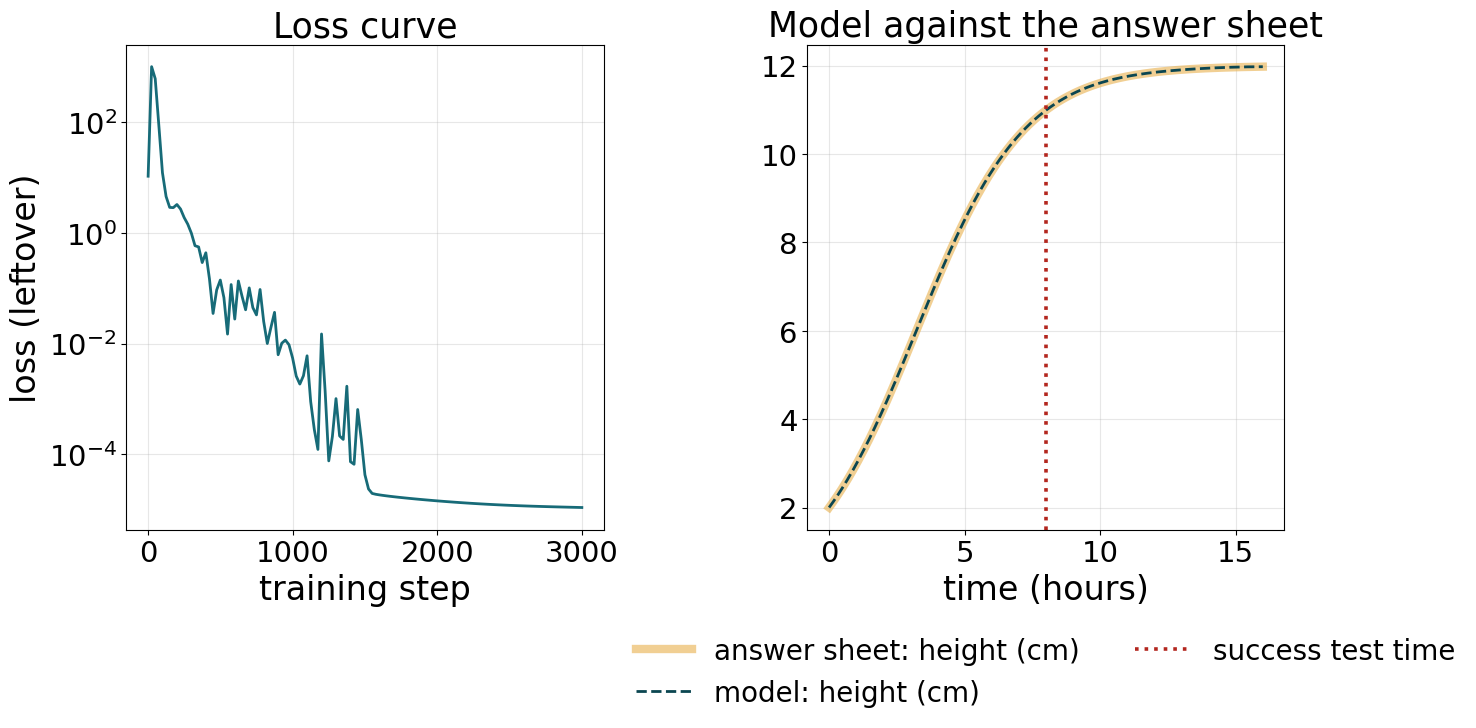

Biggest error against the answer sheet: 0.0049
Success test: at 8 hours, the model says 10.99 and the answer sheet says 10.99.
  Difference 0.000683, allowed 0.1: PASSED
Training time: 3 seconds. Model size: 1153 numbers. Checking points: 200.
Saved as class_law_model.png.


In [4]:
# ---------- THE CLASS EXAMPLE: a sourdough starter ----------
r     = 0.5      # how fast it grows, per hour        (source: a baking book)
K     = 12.0     # the top of the jar, in cm          (source: I measured the jar)
H0    = 2.0      # the starting height, in cm
t_end = 16.0     # look from 0 to 16 hours

def rate(t, H):                          # how fast the height changes, at time t
    return r * H * (1 - H / K)           # <- THE LAW, as one line of code

def exact(t):                            # the exact formula: the answer sheet
    return K / (1 + (K / H0 - 1) * onp.exp(-r * t))

check_time = 8.0          # success test: the height at 8 hours ...
check_tolerance = 0.1     # ... is within 0.1 cm of the answer sheet
t = onp.linspace(0, t_end, 400)
law_model = learn_law(rate, H0, t_end)
law_report = report(law_model, t, exact(t), ["height (cm)"], "hours", check_time, check_tolerance, picture="class_law_model.png")

### Test 1 · New points
A small error only covers the points that were checked. Test the model at **1,000 new moments** it was never checked at.

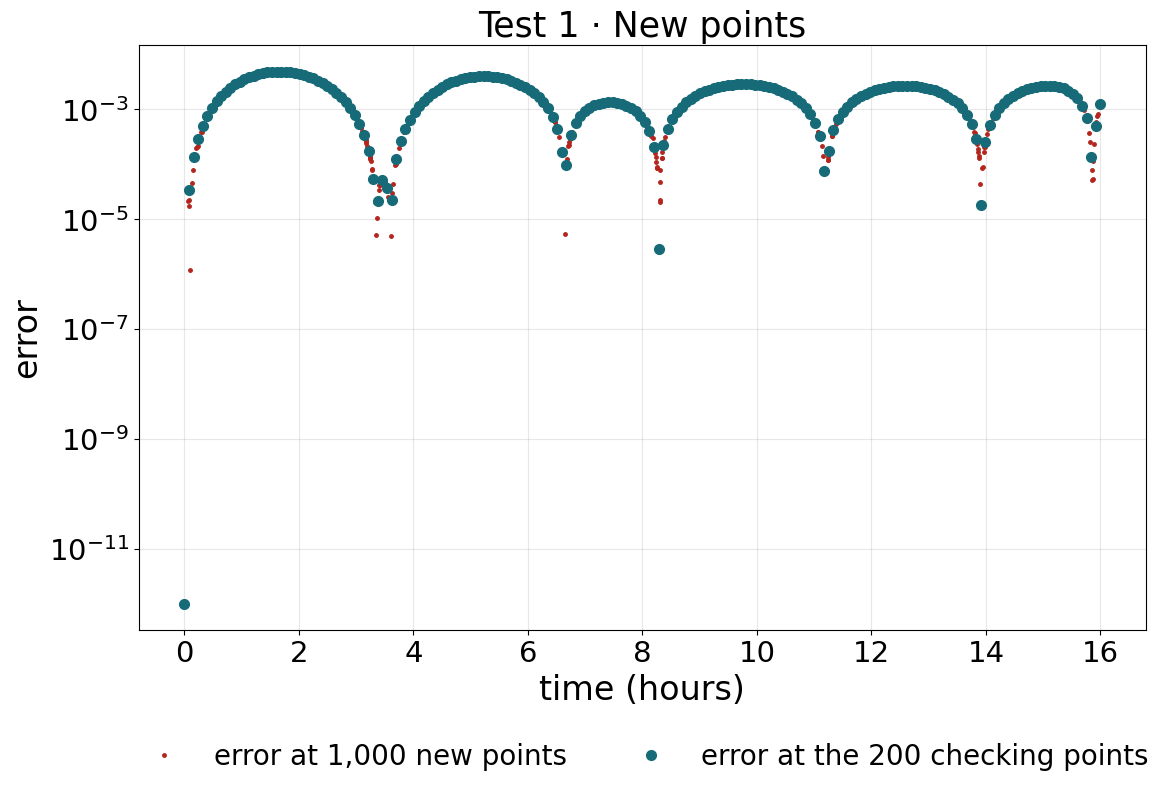

Test 1 · New points: biggest error at the checking points 0.004879; at 1,000 new points 0.00488.
  PASSED: the model is just as good between the checking points.


In [5]:
class_t1 = new_points_test(law_model, t, exact(t), t_end, ["height (cm)"], "hours")

### Test 2 · Something that must always be true
Ask three questions of the law: *what can never happen? what must stay the same? what can only go one way?* For the starter: it **never rises above the top of the jar**, and it **never shrinks**.

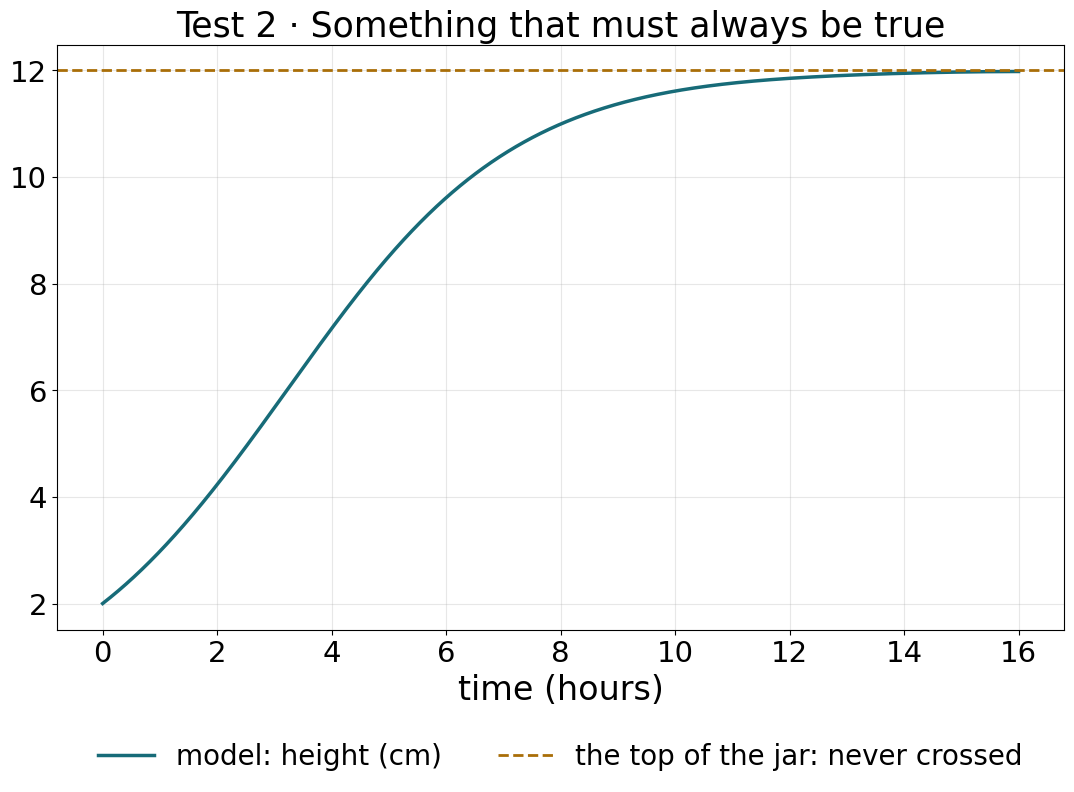

Test 2 · Must always be true: the rule holds at 100.0% of 2,000 moments.
  PASSED.


In [6]:
def must_hold(t, H, dH):                 # H: the model's height; dH: how fast it changes
    return (H <= K + 1e-3) & (dH >= -1e-6)   # never above the top of the jar, and never shrinking
class_t2 = must_hold_test(law_model, t_end, must_hold, ["height (cm)"], "hours", lines=[(K, "the top of the jar: never crossed")])

### Test 3 · The wrong-law test
Change **one number** in the law by **20%**, train again, and see how far the answer moves. Would the model's **own score** (its loss) have warned you?

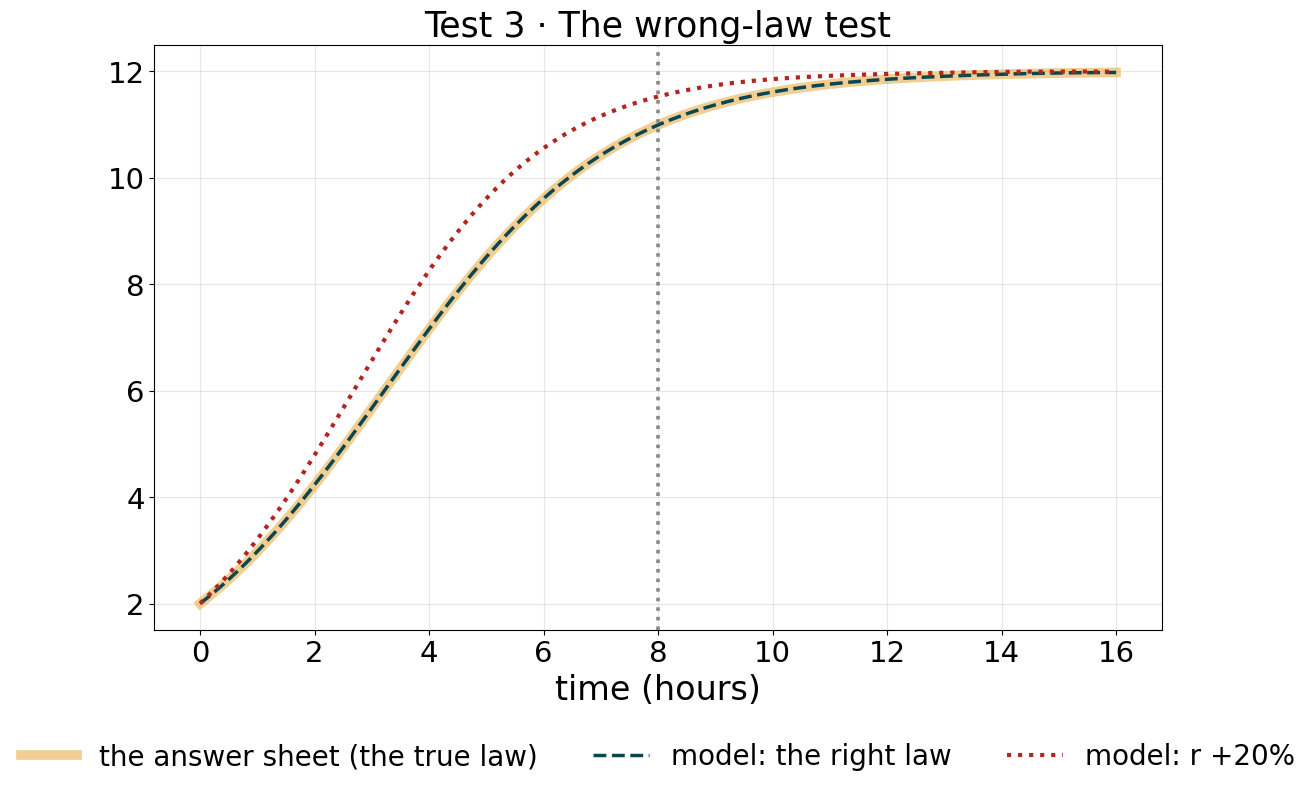

Test 3 · Wrong law: with r +20%, the answer at 8 hours moves from 10.99 to 11.53 (a change of 0.534).
  The model's own score (loss): right law 1.1e-05, wrong law 1.2e-05. The score did NOT warn you: the wrong-law model obeys its wrong law just as well.


In [9]:
class_t3 = wrong_law_test(rate, H0, t_end, "r", globals(), t, exact(t), "hours", check_time, right_result=law_model)

### Optional · Find an unknown number
Pretend **r** is unknown. From **5 noisy readings**, find the value that fits best.

In [10]:
class_find = find_number(rate, H0, t_end, "r", globals(), t, exact(t))

Optional · From 5 noisy readings, r is estimated as 0.4738 (the true value is 0.5; off by 5.2%).


### What the law leaves out, and your README
Your model cannot know what the law leaves out, so **you must say it**. The next cell prints a **Checks** table to paste into your README on GitHub.

In [11]:
readme_results("sourdough starter", class_t1, class_t2, class_t3, "temperature, the kind of flour, and how often the starter is fed.")


---------- paste this into your README.md, under ## Checks ----------

| Check | Result |
|---|---|
| New points | Biggest error 0.00488 at the checking points, 0.00488 at 1,000 new points |
| Must always be true | Holds at 100.0% of 2,000 moments |
| 20% wrong-law test | The answer moves by 0.534; the model's own score did not warn us |

**What the law leaves out:** temperature, the kind of flour, and how often the starter is fed.


### Put it on GitHub (15 minutes, once)
1. Sign in at **github.com** (create a free account if you need one), click **New repository**, name it (for example `aiml-capstone`), tick **Add a README file**, and **Create repository**.
2. Download your notebooks from Colab (**File → Download → Download .ipynb**): Weeks 7 to 10.
3. In your repository, click **Add file → Upload files**, drop in the notebooks and your pictures, and **Commit changes**.
4. Click **README.md → ✏️ edit**, paste the starter README from the **Project templates** on Tutors, fill it in, and paste your **Checks** table. **Commit changes**.
5. The notebooks fix their random starting point (the *seed*), so anyone who runs them gets the same results. Keep it that way.

## Part 2 · ✏️ YOUR TESTS, if one thing changes over time
Paste in your **Week 8 YOUR TURN cell** below, then fill in the three new lines in the cell after it.

In [16]:
# ✏️ YOUR TURN
# Project: Predicting Coffee Cooling
# Scientific law: Newton's Law of Cooling

name = "Coffee Temperature (°C)"
time_unit = "minutes"

# Scientific parameters

a = 0.05
# Cooling constant
# Unit: min^-1

b = 22.0
# Ambient room temperature
# Unit: °C

start = 85.0
# Initial coffee temperature
# Unit: °C


t_end = 60.0
# Simulation duration in minutes

# Newton's Law of Cooling
def my_rate(t, y):
    return -a * (y - b)

# Analytical solution
HAS_EXACT = True

def my_exact(t):
    return b + (start - b) * onp.exp(-a * t)

# Success test
check_time = 30.0
check_tolerance = 0.5

print("Coffee cooling law is loaded.")
print("Now run the next cell.")

Coffee cooling law is loaded.
Now run the next cell.


In [19]:
# Test 2: Physical constraints
def must_hold(t, y, dy):
    return (
        (y >= b - 1e-3) &
        (y <= start + 1e-3) &
        (dy <= 1e-6)
    )
# Test 3: Change cooling constant by 20%
wrong_number = "a"
# Model limitations
leaves_out = (
    "Evaporation, airflow, cup material, coffee volume "
    "and variations in room temperature."
)
print("Coffee cooling validation tests configured.")

Coffee cooling validation tests configured.


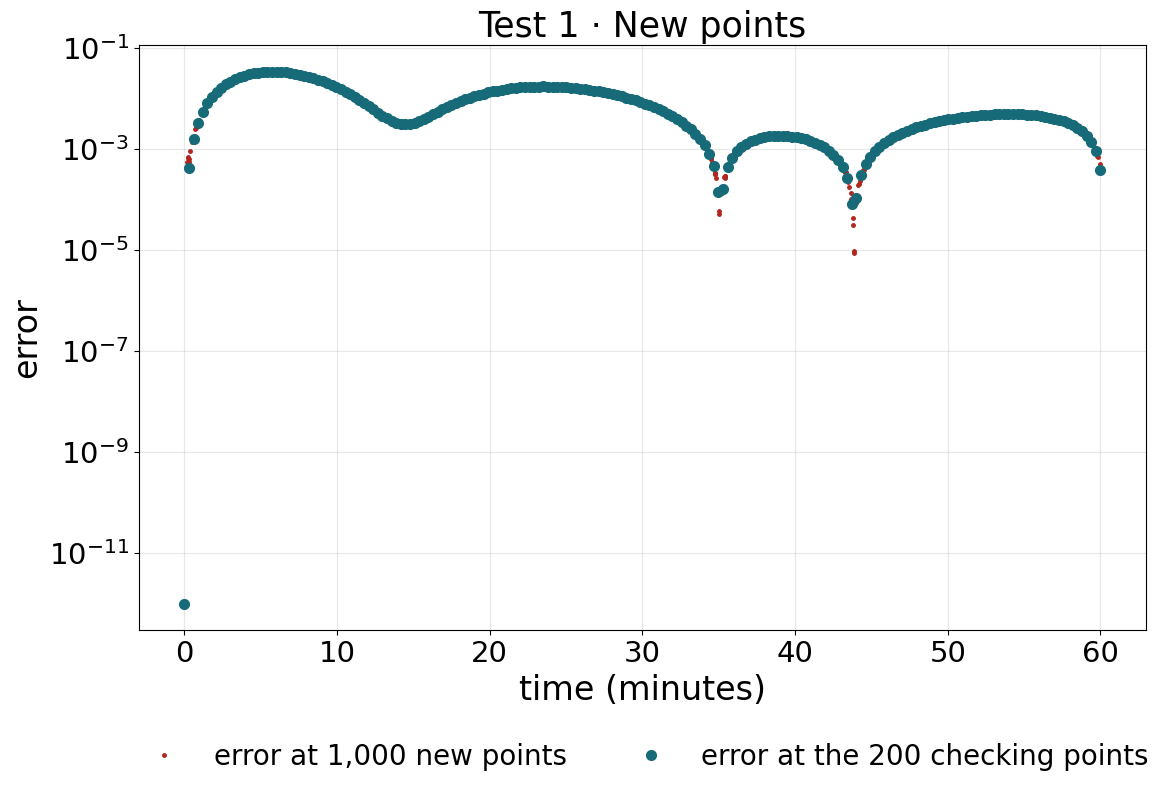

Test 1 · New points: biggest error at the checking points 0.03341; at 1,000 new points 0.03363.
  PASSED: the model is just as good between the checking points.


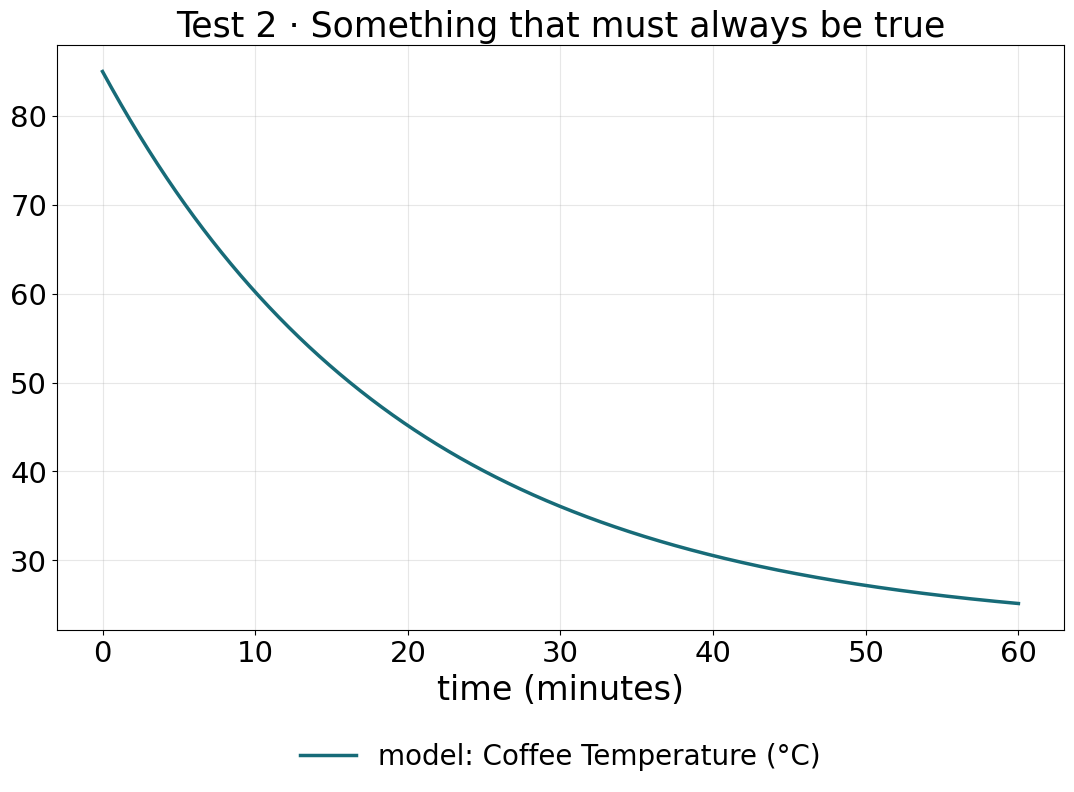

Test 2 · Must always be true: the rule holds at 100.0% of 2,000 moments.
  PASSED.


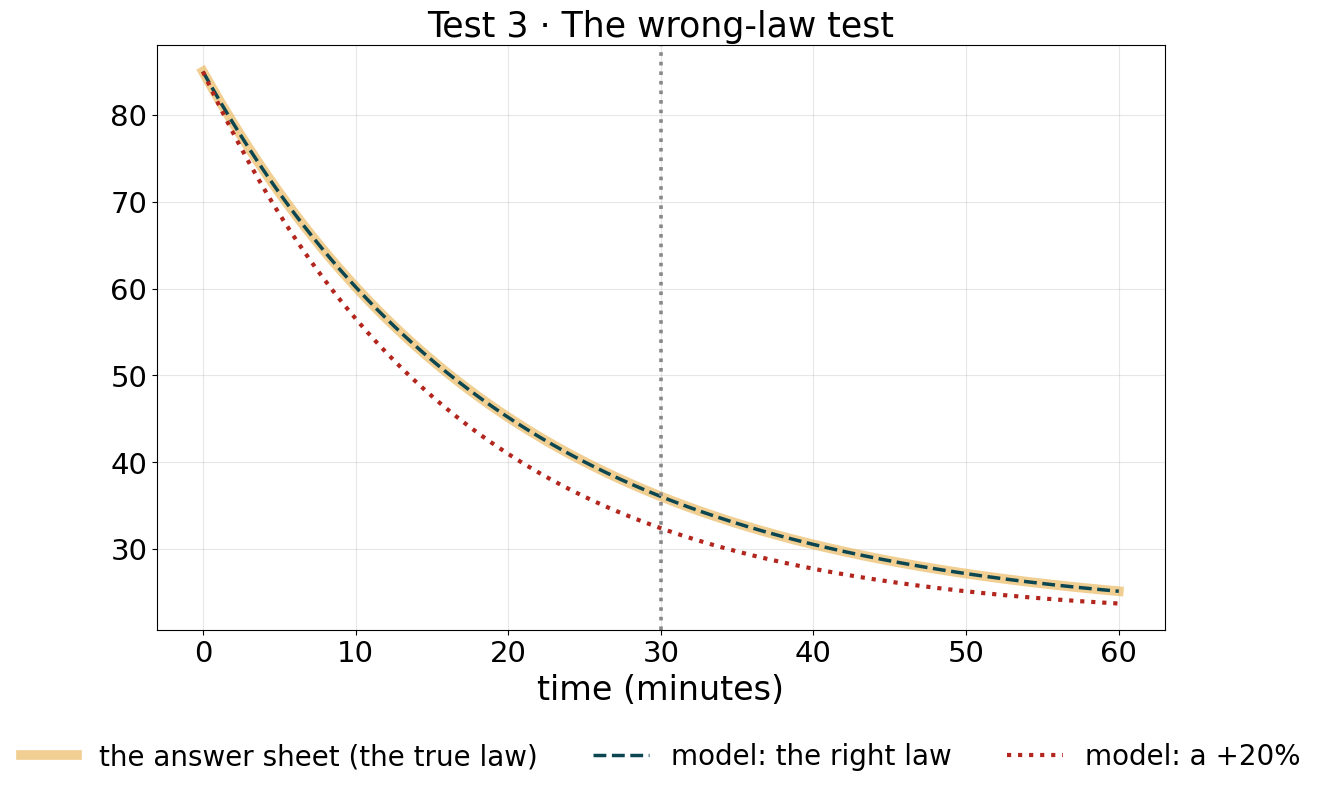

Test 3 · Wrong law: with a +20%, the answer at 30 minutes moves from 36.06 to 32.4 (a change of 3.66).
  The model's own score (loss): right law 7.8e-07, wrong law 1.9e-06. The score did NOT warn you: the wrong-law model obeys its wrong law just as well.
Optional · From 5 noisy readings, a is estimated as 0.05312 (the true value is 0.05; off by 6.2%).

---------- paste this into your README.md, under ## Checks ----------

| Check | Result |
|---|---|
| New points | Biggest error 0.0334 at the checking points, 0.0336 at 1,000 new points |
| Must always be true | Holds at 100.0% of 2,000 moments |
| 20% wrong-law test | The answer moves by 3.66; the model's own score did not warn us |

**What the law leaves out:** Evaporation, airflow, cup material, coffee volume and variations in room temperature.


In [20]:
# Your three tests, and your README table. Just run this cell (about 20 seconds).
t = onp.linspace(0, t_end, 400)
sheet = my_exact(t) if HAS_EXACT else solve_ivp(lambda tt, y: [float(my_rate(tt, y[0]))], (0, t_end), [start], t_eval=t, rtol=1e-8, atol=1e-10).y[0]
my_law = learn_law(my_rate, start, t_end)
my_t1 = new_points_test(my_law, t, sheet, t_end, [name], time_unit)
my_t2 = must_hold_test(my_law, t_end, must_hold, [name], time_unit)
my_t3 = wrong_law_test(my_rate, start, t_end, wrong_number, globals(), t, sheet, time_unit, check_time, right_result=my_law)
my_find = find_number(my_rate, start, t_end, wrong_number, globals(), t, sheet)
readme_results(name, my_t1, my_t2, my_t3, leaves_out)

## Part 3 · ✏️ YOUR TESTS, if two or three things change each other
Paste in your Week 8 Part 3 cell, fill in the new lines, and run.

In [ ]:
# ✏️ YOUR TURN (only if your law has two or three things that change each other).
names  = ["tank A (litres)", "tank B (litres)"]   # <-- one name per thing
k1 = 0.3                     # <-- a number    (unit, source)
k2 = 0.1                     # <-- a number    (unit, source)
starts = [10.0, 0.0]         # <-- starting values, one per thing
t_end3 = 30.0                # <-- how long to look
time_unit3 = "minutes"       # <-- your unit of time

def my_rates(t, y):
    A, B = y                 # <-- one short name per thing, in the same order as names
    dA = -k1 * A             # <-- how fast the first thing changes
    dB = k1 * A - k2 * B     # <-- how fast the second thing changes
    return [dA, dB]          # <-- list them all, in the same order

which = 1                    # <-- which thing your success test checks (0 = first, 1 = second, ...)
check_time3 = 15.0           # <-- your success test: the time to check ...
check_tolerance3 = 0.2       # <-- ... and how close it must be
print("Your law is loaded. Now run the next cell.")

In [ ]:
# ✏️ YOUR TURN: the three new lines for this week.
def must_hold3(t, y, dy):                # y and dy hold one row per thing, in your order
    A, B = y
    return (A >= -1e-6) & (B >= -1e-6) & (A + B <= starts[0] + starts[1] + 1e-3)   # <-- placeholder: never negative, and no water created
wrong_number3 = "k1"                     # <-- the number to change by 20%
leaves_out3 = "evaporation, and the shape of the pipes."   # <-- what your law leaves out

In [ ]:
# Your three tests. Just run this cell.
t3 = onp.linspace(0, t_end3, 300)
sheet3 = solve_ivp(lambda tt, y: onp.asarray([float(v) for v in my_rates(tt, y)]), (0, t_end3), starts, t_eval=t3, rtol=1e-8, atol=1e-10).y
my_law3 = learn_law(my_rates, starts, t_end3)
my3_t1 = new_points_test(my_law3, t3, sheet3, t_end3, names, time_unit3)
my3_t2 = must_hold_test(my_law3, t_end3, must_hold3, names, time_unit3)
my3_t3 = wrong_law_test(my_rates, starts, t_end3, wrong_number3, globals(), t3, sheet3, time_unit3, check_time3, which=which, right_result=my_law3)
readme_results(names[0], my3_t1, my3_t2, my3_t3, leaves_out3)

## Part 4 · ✏️ YOUR TESTS, if it changes over time and along a line
Paste in your Week 8 Part 4 cell, fill in the new lines, and run (about two minutes).

In [ ]:
# ✏️ YOUR TURN (only if your law changes over time and along a line).
D = 1.0                      # <-- how fast it spreads   (km² per year, source: ...)
g = 1.0                      # <-- how fast it grows     (per year, source: ...)
L = 40.0                     # <-- length of the line    (km)
t_end4 = 8.0                 # <-- how long to look      (years)
name4 = "share of the coastline settled"   # <-- what changes

def my_line_law(u, u_x, u_xx):              # how fast it changes at a point on the line
    return D * u_xx + g * u * (1 - u)       # <-- YOUR LAW (Week 7's "bend" is u_xx here)

def u0(x):                                  # <-- the starting values along the line
    return np.exp(-x**2 / 4)

times = [0, 2, 4, 6, 8]      # <-- moments to draw (the last one is t_end4)
check_place, check_time4, check_tolerance4 = 10.0, 8.0, 0.05   # <-- your success test
print("Your law is loaded. Now run the next cell (about a minute).")

In [ ]:
# ✏️ YOUR TURN: the three new lines for this week.
def must_hold4(x, U):                    # U: the model's values, one row per moment, one column per place
    return (U >= -0.02) & (U <= 1.02)    # <-- placeholder: the settled share stays between 0 and 1
wrong_number4 = "g"                      # <-- the number to change by 20%
leaves_out4 = "rivers and roads that block the spread, and the weather."   # <-- what your law leaves out

In [ ]:
# Your three tests. Just run this cell (about two minutes).
x4, sheet4 = line_answer_sheet(my_line_law, lambda xx: onp.asarray(u0(xx)), L, t_end4, times)
my_law4 = learn_line_law(my_line_law, u0, L, t_end4)
my4_t1, my4_t2, my4_t3 = line_tests(my_line_law, u0, L, t_end4, my_law4, x4, sheet4, times, must_hold4, wrong_number4, globals(), check_place, check_time4, name4)
readme_results(name4, my4_t1, my4_t2, my4_t3, leaves_out4)

## Done · What to hand in (the Week 10 form)
- **Part A:** your two questions, the pages they pointed to, and whether one answer was right when you checked the page.
- **Your GitHub link.**
- **The result of each test** (the README table above).
- **Your sentence on what your law leaves out.**
- **How you used AI** this week, for example for your README or your tests.